#  Preparação, Modelagem e Avaliação do Risco de Incêndios no Brasil

## Projeto Final — TripleTen

Este notebook dá continuidade à análise exploratória realizada anteriormente e desenvolve as etapas de preparação, integração e modelagem dos dados do projeto.

O objetivo é construir um modelo de Machine Learning capaz de classificar o **nível de risco de fogo em três categorias: Baixo, Médio e Alto**, utilizando informações meteorológicas, temporais, geográficas e de cobertura do solo.

É importante destacar que o modelo **não prevê diretamente a ocorrência de um novo incêndio**. A variável-alvo é construída a partir do indicador `risco_fogo` presente na base de queimadas, e a análise considera observações município-dia disponíveis nessa base.

Ao longo do notebook serão realizadas as seguintes etapas:

1. Preparação e limpeza das bases de dados;
2. Agregação dos registros por município e dia;
3. Integração dos dados de queimadas, meteorologia e MapBiomas;
4. Construção da variável-alvo;
5. Seleção das variáveis e prevenção de vazamento de dados (*data leakage*);
6. Separação dos conjuntos de treino e teste;
7. Construção de um modelo baseline;
8. Treinamento e comparação dos modelos de classificação;
9. Validação temporal do modelo selecionado;
10. Análise da importância das variáveis;
11. Interpretação dos resultados, limitações e próximos passos.

## 1. Configuração do ambiente e fontes de dados

O projeto combina diferentes fontes de informação para representar fatores associados ao risco de fogo:

- **Queimadas:** registros de focos detectados e o indicador de risco de fogo;
- **INMET:** condições meteorológicas observadas pelas estações;
- **Cadastro de estações:** localização geográfica das estações meteorológicas;
- **MapBiomas:** características de cobertura e uso do solo dos municípios.

A combinação dessas fontes permite construir uma base município-dia com informações temporais, meteorológicas, geográficas e ambientais para a etapa de modelagem.

In [2]:
import pandas as pd
import numpy as np
from pathlib import Path

# Caminhos do projeto
PROJECT_ROOT = Path.cwd().parent
DATA_RAW = PROJECT_ROOT / "data" / "raw"
DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"

print("Ambiente configurado com sucesso!")
print(f"Dados brutos: {DATA_RAW}")
print(f"Dados processados: {DATA_PROCESSED}")

Ambiente configurado com sucesso!
Dados brutos: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\raw
Dados processados: c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed


In [3]:
# Definir os arquivos utilizados no projeto

arquivos = {
    "queimadas": DATA_RAW / "queimadas_2024_2025.csv",
    "mapbiomas": DATA_RAW / "MapBiomas.csv",
    "estacoes": DATA_RAW / "BDMEP-estacao.csv",
    "meteorologia": DATA_RAW / "BDMEP-2025.csv"
}

# Verificar se todos os arquivos existem
for nome, caminho in arquivos.items():
    print(f"{nome:15} | Existe: {caminho.exists()} | {caminho.name}")

queimadas       | Existe: True | queimadas_2024_2025.csv
mapbiomas       | Existe: True | MapBiomas.csv
estacoes        | Existe: True | BDMEP-estacao.csv
meteorologia    | Existe: True | BDMEP-2025.csv


## 1. Preparação da base de queimadas

A base de queimadas será tratada primeiro por ser a principal fonte de informações sobre ocorrências e risco de fogo.

Nesta etapa serão analisadas as variáveis relevantes, os tipos de dados, valores ausentes e possíveis registros duplicados antes da integração com as demais bases.

In [4]:
# Diagnóstico do arquivo de queimadas
caminho_queimadas = arquivos["queimadas"]

with open(caminho_queimadas, "r", encoding="utf-8", errors="replace") as arquivo:
    for i in range(5):
        linha = arquivo.readline()
        print(f"Linha {i + 1}:")
        print(repr(linha[:1000]))
        print("-" * 80)

Linha 1:
'\ufeffano;mes;data_hora;bioma;sigla_uf;sigla_uf_nome;id_municipio;id_municipio_nome;latitude;longitude;satelite;dias_sem_chuva;precipitacao;risco_fogo;potencia_radiativa_fogo\n'
--------------------------------------------------------------------------------
Linha 2:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;MG;Minas Gerais;3166907;Serrania;-21.56454;-46.03047;NPP-375D;19.0;0.0;1.0;7.3\n'
--------------------------------------------------------------------------------
Linha 3:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;ES;Espírito Santo;3202652;Irupi;-20.27151;-41.69187;NPP-375D;34.0;0.0;1.0;3.8\n'
--------------------------------------------------------------------------------
Linha 4:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3300308;Barra do Piraí;-22.42786;-43.81413;NPP-375D;18.0;0.0;1.0;2.5\n'
--------------------------------------------------------------------------------
Linha 5:
'2024;9;2024-09-13 04:29:00;Mata Atlântica;RJ;Rio de Janeiro;3303708;P

In [5]:
# Procurar linhas com quantidade incorreta de campos

caminho_queimadas = arquivos["queimadas"]

linhas_problematicas = []
campos_esperados = 15

with open(
    caminho_queimadas,
    "r",
    encoding="utf-8-sig",
    errors="replace"
) as arquivo:

    # Ignorar cabeçalho
    next(arquivo)

    for numero_linha, linha in enumerate(arquivo, start=2):

        quantidade_campos = len(linha.rstrip("\n").split(";"))

        if quantidade_campos != campos_esperados:
            linhas_problematicas.append(
                (numero_linha, quantidade_campos, linha[:300])
            )

            # Não precisamos procurar milhares agora
            if len(linhas_problematicas) >= 20:
                break

print(f"Linhas problemáticas encontradas: {len(linhas_problematicas)}")

for numero, campos, conteudo in linhas_problematicas:
    print("\n" + "=" * 70)
    print(f"Linha: {numero}")
    print(f"Quantidade de campos: {campos}")
    print(f"Conteúdo: {conteudo}")

Linhas problemáticas encontradas: 0


In [6]:
# Teste de leitura antes de carregar a base completa

queimadas_teste = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    engine="python",
    nrows=100_000
)

print("Leitura realizada com sucesso!")
print(f"Linhas: {queimadas_teste.shape[0]:,}")
print(f"Colunas: {queimadas_teste.shape[1]}")

queimadas_teste.head()

Leitura realizada com sucesso!
Linhas: 100,000
Colunas: 15


,ano,mes,data_hora,bioma,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,latitude,longitude,satelite,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo
0,2024,9,2024-09-13 04:29:00,Mata Atlântica,MG,Minas Gerais,3166907,Serrania,-21.56454,-46.03047,NPP-375D,19.0,0.0,1.0,7.3
1,2024,9,2024-09-13 04:29:00,Mata Atlântica,ES,Espírito Santo,3202652,Irupi,-20.27151,-41.69187,NPP-375D,34.0,0.0,1.0,3.8
2,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3300308,Barra do Piraí,-22.42786,-43.81413,NPP-375D,18.0,0.0,1.0,2.5
3,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303708,Paraíba do Sul,-22.18328,-43.35031,NPP-375D,18.0,0.0,1.0,26.5
4,2024,9,2024-09-13 04:29:00,Mata Atlântica,RJ,Rio de Janeiro,3303906,Petrópolis,-22.53255,-43.13242,NPP-375D,-999.0,0.0,1.0,2.0


In [7]:
# Testar o parser padrão do pandas (mais rápido)

queimadas_teste_c = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    nrows=100_000,
    low_memory=False
)

print("Teste com parser padrão concluído!")
print(f"Linhas: {queimadas_teste_c.shape[0]:,}")
print(f"Colunas: {queimadas_teste_c.shape[1]}")

print("\nColunas encontradas:")
print(queimadas_teste_c.columns.tolist())

Teste com parser padrão concluído!
Linhas: 100,000
Colunas: 15

Colunas encontradas:
['ano', 'mes', 'data_hora', 'bioma', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'latitude', 'longitude', 'satelite', 'dias_sem_chuva', 'precipitacao', 'risco_fogo', 'potencia_radiativa_fogo']


In [8]:
# Carregar a base completa de queimadas
# utilizando apenas as variáveis relevantes para o projeto

colunas_queimadas = [
    "ano",
    "mes",
    "data_hora",
    "bioma",
    "sigla_uf",
    "sigla_uf_nome",
    "id_municipio",
    "id_municipio_nome",
    "latitude",
    "longitude",
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

queimadas = pd.read_csv(
    arquivos["queimadas"],
    sep=";",
    encoding="utf-8-sig",
    usecols=colunas_queimadas,
    low_memory=False
)

print("Base completa de queimadas carregada com sucesso!")
print(f"Linhas: {queimadas.shape[0]:,}")
print(f"Colunas: {queimadas.shape[1]}")
print(f"Memória utilizada: {queimadas.memory_usage(deep=True).sum() / 1024**2:,.2f} MB")

Base completa de queimadas carregada com sucesso!
Linhas: 8,226,944
Colunas: 14
Memória utilizada: 3,470.85 MB


In [9]:
# Converter data_hora para formato datetime

queimadas["data_hora"] = pd.to_datetime(
    queimadas["data_hora"],
    errors="coerce"
)

print("Tipo de data_hora:")
print(queimadas["data_hora"].dtype)

print("\nDatas inválidas após conversão:")
print(queimadas["data_hora"].isna().sum())

print("\nPeríodo disponível:")
print("Data inicial:", queimadas["data_hora"].min())
print("Data final:", queimadas["data_hora"].max())

Tipo de data_hora:
datetime64[us]

Datas inválidas após conversão:
0

Período disponível:
Data inicial: 2024-01-01 00:06:16
Data final: 2025-02-12 23:10:00


In [10]:
# Verificar registros duplicados na base completa

duplicatas = queimadas.duplicated().sum()

print(f"Total de registros: {len(queimadas):,}")
print(f"Registros duplicados: {duplicatas:,}")
print(f"Percentual de duplicatas: {duplicatas / len(queimadas) * 100:.4f}%")

Total de registros: 8,226,944
Registros duplicados: 0
Percentual de duplicatas: 0.0000%


In [11]:
# Analisar valores ausentes na base completa de queimadas

ausentes_queimadas = pd.DataFrame({
    "quantidade": queimadas.isna().sum(),
    "percentual": queimadas.isna().mean() * 100
})

ausentes_queimadas = ausentes_queimadas[
    ausentes_queimadas["quantidade"] > 0
].sort_values("percentual", ascending=False)

ausentes_queimadas["percentual"] = (
    ausentes_queimadas["percentual"].round(2)
)

print("VALORES AUSENTES - QUEIMADAS")
print("=" * 50)

ausentes_queimadas

VALORES AUSENTES - QUEIMADAS


,quantidade,percentual
potencia_radiativa_fogo,340724,4.14
precipitacao,112670,1.37
dias_sem_chuva,112670,1.37
risco_fogo,112670,1.37
bioma,1,0.00


In [12]:
# Analisar a variável risco_fogo

print("ESTATÍSTICAS DE RISCO_FOGO")
print("=" * 50)

print(queimadas["risco_fogo"].describe())

print("\nQuantidade de valores únicos:")
print(queimadas["risco_fogo"].nunique())

print("\nMenor valor:")
print(queimadas["risco_fogo"].min())

print("\nMaior valor:")
print(queimadas["risco_fogo"].max())

print("\nValores mais frequentes:")
print(
    queimadas["risco_fogo"]
    .value_counts(dropna=False)
    .head(20)
)

ESTATÍSTICAS DE RISCO_FOGO
count    8.114274e+06
mean    -1.021298e+01
std      1.045882e+02
min     -9.990000e+02
25%      8.200000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores únicos:
102

Menor valor:
-999.0

Maior valor:
1.0

Valores mais frequentes:
risco_fogo
 1.00      4938904
 NaN        112670
 0.00       111421
 0.99       108682
 0.98        91385
-999.00      89779
 0.97        84433
 0.96        78620
 0.95        75454
 0.94        71237
 0.93        67371
 0.92        65501
 0.91        61278
 0.90        59495
 0.89        58551
 0.01        56591
 0.88        53818
 0.87        53535
 0.86        53527
 0.85        49451
Name: count, dtype: int64


In [13]:
# Investigar valores -999 em risco_fogo

qtd_999 = (queimadas["risco_fogo"] == -999).sum()

print("ANÁLISE DO VALOR -999")
print("=" * 50)

print(f"Quantidade de -999: {qtd_999:,}")
print(
    f"Percentual de -999: "
    f"{qtd_999 / len(queimadas) * 100:.2f}%"
)

# Considerar apenas valores entre 0 e 1 para análise
risco_valido = queimadas.loc[
    queimadas["risco_fogo"].between(0, 1),
    "risco_fogo"
]

print("\nESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1")
print("=" * 50)
print(risco_valido.describe())

print("\nQuantidade de valores válidos:")
print(f"{len(risco_valido):,}")

print("\nQuantidade de valores únicos válidos:")
print(risco_valido.nunique())

ANÁLISE DO VALOR -999
Quantidade de -999: 89,779
Percentual de -999: 1.09%

ESTATÍSTICAS APENAS DOS VALORES ENTRE 0 E 1
count    8.024495e+06
mean     8.496855e-01
std      2.773445e-01
min      0.000000e+00
25%      8.400000e-01
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: risco_fogo, dtype: float64

Quantidade de valores válidos:
8,024,495

Quantidade de valores únicos válidos:
101


In [14]:
# Analisar a distribuição dos valores válidos de risco_fogo

faixas_risco = pd.cut(
    risco_valido,
    bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0],
    include_lowest=True
)

distribuicao_risco = pd.DataFrame({
    "quantidade": faixas_risco.value_counts(sort=False),
    "percentual": faixas_risco.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_risco["percentual"] = (
    distribuicao_risco["percentual"].round(2)
)

print("DISTRIBUIÇÃO DE RISCO_FOGO")
print("=" * 50)

distribuicao_risco

DISTRIBUIÇÃO DE RISCO_FOGO


,quantidade,percentual
risco_fogo,,
"(-0.001, 0.2]",566176,7.06
"(0.2, 0.4]",301198,3.75
"(0.4, 0.6]",390026,4.86
"(0.6, 0.8]",610563,7.61
"(0.8, 1.0]",6156532,76.72


In [15]:
# Verificar os valores de risco_fogo mais frequentes

frequencia_risco = (
    risco_valido
    .value_counts()
    .sort_index()
    .reset_index()
)

frequencia_risco.columns = ["risco_fogo", "quantidade"]

frequencia_risco["percentual"] = (
    frequencia_risco["quantidade"]
    / len(risco_valido)
    * 100
).round(2)

print("20 MAIORES VALORES DE RISCO_FOGO")
print("=" * 50)

frequencia_risco.tail(20)

20 MAIORES VALORES DE RISCO_FOGO


,risco_fogo,quantidade,percentual
81,0.81,44623,0.56
82,0.82,47218,0.59
83,0.83,46225,0.58
84,0.84,47224,0.59
85,0.85,49451,0.62
86,0.86,53527,0.67
87,0.87,53535,0.67
88,0.88,53818,0.67
89,0.89,58551,0.73
90,0.90,59495,0.74


In [16]:
# Classificar risco_fogo segundo as faixas oficiais do INPE
# Apenas para análise exploratória neste momento

risco_inpe = pd.cut(
    risco_valido,
    bins=[-0.001, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=["Mínimo", "Baixo", "Médio", "Alto", "Crítico"],
    include_lowest=True
)

distribuicao_inpe = pd.DataFrame({
    "quantidade": risco_inpe.value_counts(sort=False),
    "percentual": risco_inpe.value_counts(
        normalize=True,
        sort=False
    ) * 100
})

distribuicao_inpe["percentual"] = (
    distribuicao_inpe["percentual"].round(2)
)

print("DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE")
print("=" * 55)

distribuicao_inpe

DISTRIBUIÇÃO SEGUNDO AS CATEGORIAS DO INPE


,quantidade,percentual
risco_fogo,,
Mínimo,489737,6.10
Baixo,377637,4.71
Médio,647319,8.07
Alto,1207778,15.05
Crítico,5302024,66.07


In [17]:
# Converter o código inválido -999 em valor ausente

queimadas["risco_fogo"] = queimadas["risco_fogo"].replace(
    -999,
    np.nan
)

print("TRATAMENTO DE RISCO_FOGO")
print("=" * 50)

print(
    f"Valores -999 restantes: "
    f"{(queimadas['risco_fogo'] == -999).sum():,}"
)

print(
    f"Valores ausentes em risco_fogo: "
    f"{queimadas['risco_fogo'].isna().sum():,}"
)

print(
    f"Valores válidos: "
    f"{queimadas['risco_fogo'].notna().sum():,}"
)

print("\nIntervalo dos valores válidos:")
print(
    queimadas["risco_fogo"].min(),
    "a",
    queimadas["risco_fogo"].max()
)

TRATAMENTO DE RISCO_FOGO
Valores -999 restantes: 0
Valores ausentes em risco_fogo: 202,449
Valores válidos: 8,024,495

Intervalo dos valores válidos:
0.0 a 1.0


### Conclusão do tratamento inicial da base de queimadas

A base contém **8.226.944 registros** e não foram identificadas duplicatas completas. O período analisado vai de **1º de janeiro de 2024 a 12 de fevereiro de 2025**.

Durante a análise da variável `risco_fogo`, foram encontrados **89.779 registros com valor -999**, equivalentes a aproximadamente **1,09% da base**. Como esse valor está fora do intervalo válido do indicador, de 0 a 1, ele foi interpretado como código de ausência de informação e convertido para `NaN`.

Após esse tratamento, permaneceram **8.024.495 valores válidos de `risco_fogo`**, todos dentro do intervalo esperado de 0 a 1.

Também foi observada uma forte concentração dos valores de risco nas faixas superiores, indicando desde esta etapa que a variável de interesse apresenta uma distribuição desequilibrada. Esse comportamento será considerado posteriormente na construção da variável-alvo e na escolha das métricas de avaliação dos modelos.

In [18]:
# Verificar se os valores ausentes ocorrem nas mesmas linhas

colunas_verificar = [
    "dias_sem_chuva",
    "precipitacao",
    "risco_fogo",
    "potencia_radiativa_fogo"
]

print("PADRÕES DE VALORES AUSENTES")
print("=" * 60)

padroes_ausentes = (
    queimadas[colunas_verificar]
    .isna()
    .value_counts()
    .reset_index(name="quantidade")
)

padroes_ausentes["percentual"] = (
    padroes_ausentes["quantidade"]
    / len(queimadas)
    * 100
).round(2)

padroes_ausentes.head(10)

PADRÕES DE VALORES AUSENTES


,dias_sem_chuva,precipitacao,risco_fogo,potencia_radiativa_fogo,quantidade,percentual
0,False,False,False,False,7697301,93.56
1,False,False,False,True,327194,3.98
2,True,True,True,False,103316,1.26
3,False,False,True,False,85603,1.04
4,True,True,True,True,9354,0.11
5,False,False,True,True,4176,0.05


In [19]:
# Criar variável de data para futura agregação diária

queimadas["data"] = queimadas["data_hora"].dt.normalize()

print("NOVA VARIÁVEL DE DATA")
print("=" * 50)

print("Tipo:")
print(queimadas["data"].dtype)

print("\nPeríodo:")
print("Data inicial:", queimadas["data"].min())
print("Data final:", queimadas["data"].max())

print("\nExemplo:")
print(
    queimadas[
        ["data_hora", "data", "id_municipio", "risco_fogo"]
    ].head()
)

NOVA VARIÁVEL DE DATA
Tipo:
datetime64[us]

Período:
Data inicial: 2024-01-01 00:00:00
Data final: 2025-02-12 00:00:00

Exemplo:
            data_hora       data  id_municipio  risco_fogo
0 2024-09-13 04:29:00 2024-09-13       3166907         1.0
1 2024-09-13 04:29:00 2024-09-13       3202652         1.0
2 2024-09-13 04:29:00 2024-09-13       3300308         1.0
3 2024-09-13 04:29:00 2024-09-13       3303708         1.0
4 2024-09-13 04:29:00 2024-09-13       3303906         1.0


In [20]:
# Analisar quantidade de focos por município e dia

focos_por_municipio_dia = (
    queimadas
    .groupby(["id_municipio", "data"])
    .size()
)

print("FOCOS POR MUNICÍPIO/DIA")
print("=" * 50)

print(f"Total de combinações município-dia: {len(focos_por_municipio_dia):,}")

print("\nEstatísticas:")
print(focos_por_municipio_dia.describe())

print("\nMaior número de focos em um município no mesmo dia:")
print(focos_por_municipio_dia.max())


FOCOS POR MUNICÍPIO/DIA
Total de combinações município-dia: 324,219

Estatísticas:
count    324219.000000
mean         25.374651
std         166.714562
min           1.000000
25%           1.000000
50%           3.000000
75%           9.000000
max       12149.000000
dtype: float64

Maior número de focos em um município no mesmo dia:
12149


In [21]:
# Verificar a variação de risco_fogo dentro do mesmo município e dia

variacao_risco_diario = (
    queimadas
    .groupby(["id_municipio", "data"])["risco_fogo"]
    .agg(["count", "min", "max", "mean"])
)

variacao_risco_diario["amplitude"] = (
    variacao_risco_diario["max"] -
    variacao_risco_diario["min"]
)

print("VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA")
print("=" * 60)

print(
    "Município-dias analisados:",
    f"{len(variacao_risco_diario):,}"
)

print(
    "Sem nenhum risco_fogo válido:",
    f"{(variacao_risco_diario['count'] == 0).sum():,}"
)

print(
    "Com apenas um valor válido:",
    f"{(variacao_risco_diario['count'] == 1).sum():,}"
)

print(
    "Com mais de um valor válido:",
    f"{(variacao_risco_diario['count'] > 1).sum():,}"
)

print("\nAmplitude de risco dentro do município/dia:")
print(variacao_risco_diario["amplitude"].describe())

VARIAÇÃO DE RISCO_FOGO POR MUNICÍPIO/DIA
Município-dias analisados: 324,219
Sem nenhum risco_fogo válido: 15,228
Com apenas um valor válido: 94,844
Com mais de um valor válido: 214,147

Amplitude de risco dentro do município/dia:
count    308991.000000
mean          0.076494
std           0.182814
min           0.000000
25%           0.000000
50%           0.000000
75%           0.030000
max           1.000000
Name: amplitude, dtype: float64


In [22]:
# Analisar a magnitude da variação diária de risco_fogo

amplitude = variacao_risco_diario["amplitude"].dropna()

print("MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO")
print("=" * 60)

limites = [0, 0.01, 0.05, 0.10, 0.20, 0.50]

for limite in limites:
    quantidade = (amplitude > limite).sum()
    percentual = quantidade / len(amplitude) * 100

    print(
        f"Amplitude > {limite:.2f}: "
        f"{quantidade:,} ({percentual:.2f}%)"
    )

MAGNITUDE DA VARIAÇÃO DIÁRIA DE RISCO
Amplitude > 0.00: 98,206 (31.78%)
Amplitude > 0.01: 93,429 (30.24%)
Amplitude > 0.05: 68,804 (22.27%)
Amplitude > 0.10: 54,816 (17.74%)
Amplitude > 0.20: 39,721 (12.86%)
Amplitude > 0.50: 16,683 (5.40%)


### Definição da unidade de análise: município-dia

Os registros originais representam focos individuais detectados por satélite, portanto um mesmo município pode apresentar vários registros no mesmo dia. Para integrar essas informações com os dados meteorológicos diários e construir uma unidade consistente para modelagem, os registros serão agregados por **município e data**.

A análise anterior mostrou que existem **324.219 combinações município-dia** e que o valor de `risco_fogo` pode variar entre diferentes focos registrados no mesmo município e dia. Por esse motivo, serão preservadas duas medidas durante a agregação:

- `risco_fogo_medio`: representa o nível médio de risco observado entre os focos do município naquele dia;
- `risco_fogo_max`: representa o maior nível de risco observado e será posteriormente utilizado como referência para a construção da variável-alvo.

Também serão agregadas informações como número de focos, precipitação, dias sem chuva e potência radiativa. Algumas dessas variáveis serão mantidas nesta etapa para análise, mas posteriormente poderão ser excluídas da modelagem para evitar vazamento de informação.

In [23]:
# Agregar a base de queimadas por município e dia

queimadas_diario = (
    queimadas
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        ano=("ano", "first"),
        mes=("mes", "first"),
        sigla_uf=("sigla_uf", "first"),
        sigla_uf_nome=("sigla_uf_nome", "first"),
        id_municipio_nome=("id_municipio_nome", "first"),
        bioma=("bioma", "first"),

        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),

        numero_focos=("data_hora", "size"),

        dias_sem_chuva=("dias_sem_chuva", "mean"),
        precipitacao_queimadas=("precipitacao", "mean"),

        risco_fogo_medio=("risco_fogo", "mean"),
        risco_fogo_max=("risco_fogo", "max"),

        potencia_radiativa_media=(
            "potencia_radiativa_fogo",
            "mean"
        ),
        potencia_radiativa_max=(
            "potencia_radiativa_fogo",
            "max"
        )
    )
)

print("BASE DIÁRIA DE QUEIMADAS")
print("=" * 60)

print(f"Linhas originais: {len(queimadas):,}")
print(f"Linhas após agregação: {len(queimadas_diario):,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nPrimeiras linhas:")
queimadas_diario.head()

BASE DIÁRIA DE QUEIMADAS
Linhas originais: 8,226,944
Linhas após agregação: 324,219
Colunas: 17

Primeiras linhas:


,id_municipio,data,ano,mes,sigla_uf,sigla_uf_nome,id_municipio_nome,bioma,latitude,longitude,numero_focos,dias_sem_chuva,precipitacao_queimadas,risco_fogo_medio,risco_fogo_max,potencia_radiativa_media,potencia_radiativa_max
0,1100015,2024-01-09,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.012145,-62.352457,8,3.0,31.38875,0.000,0.00,4.5375,6.8
1,1100015,2024-01-16,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.080470,-62.060842,5,0.0,0.22400,0.010,0.01,34.7200,50.4
2,1100015,2024-01-27,2024,1,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.720660,-62.079500,2,0.0,2.19500,0.010,0.01,2.9500,3.8
3,1100015,2024-02-09,2024,2,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-12.723245,-62.017786,10,1.0,1.01300,0.075,0.10,18.1600,45.0
4,1100015,2024-03-04,2024,3,RO,Rondônia,Alta Floresta D'Oeste,Amazônia,-13.011165,-62.348880,2,0.0,6.32500,0.010,0.01,3.8000,3.8


In [24]:
print("VALIDAÇÃO DA BASE DIÁRIA")
print("=" * 50)

print(f"Linhas: {queimadas_diario.shape[0]:,}")
print(f"Colunas: {queimadas_diario.shape[1]}")

print("\nDuplicatas município-data:")
print(
    queimadas_diario.duplicated(
        subset=["id_municipio", "data"]
    ).sum()
)

print("\nValores ausentes:")
print(
    queimadas_diario.isna()
    .sum()
    .sort_values(ascending=False)
)

VALIDAÇÃO DA BASE DIÁRIA
Linhas: 324,219
Colunas: 17

Duplicatas município-data:
0

Valores ausentes:
risco_fogo_medio            15228
risco_fogo_max              15228
dias_sem_chuva               6418
precipitacao_queimadas       6418
potencia_radiativa_max       2851
potencia_radiativa_media     2851
bioma                           1
id_municipio                    0
data                            0
latitude                        0
id_municipio_nome               0
sigla_uf_nome                   0
sigla_uf                        0
ano                             0
mes                             0
longitude                       0
numero_focos                    0
dtype: int64


In [25]:
# Carregar a base meteorológica do BDMEP

meteorologia = pd.read_csv(
    arquivos["meteorologia"],
    low_memory=False
)

print("BASE METEOROLÓGICA - BDMEP")
print("=" * 60)

print(f"Linhas: {meteorologia.shape[0]:,}")
print(f"Colunas: {meteorologia.shape[1]}")

print("\nColunas disponíveis:")
print(meteorologia.columns.tolist())

print("\nPrimeiras linhas:")
meteorologia.head()

BASE METEOROLÓGICA - BDMEP
Linhas: 4,891,176
Colunas: 21

Colunas disponíveis:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']

Primeiras linhas:


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2025,2025-05-29,13:00:00,A316,0.0,997.6,997.9,997.5,2523.7,30.7,...,31.1,28.8,18.5,15.9,53.0,41.0,41.0,106.0,9.1,4.2
1,2025,2025-01-21,16:00:00,A867,0.0,1007.7,1008.4,1007.7,3896.8,32.6,...,32.8,31.6,18.6,14.8,46.0,34.0,41.0,256.0,8.8,4.5
2,2025,2025-05-14,18:00:00,A366,0.0,958.9,959.3,958.7,2227.9,30.3,...,31.2,29.5,13.7,11.8,36.0,31.0,32.0,119.0,11.7,5.5
3,2025,2025-05-27,16:00:00,A849,0.0,971.3,972.2,971.3,2279.0,29.8,...,29.8,27.9,15.4,14.5,45.0,41.0,41.0,NaN,10.3,5.5
4,2025,2025-04-01,19:00:00,A349,0.0,959.8,959.9,959.7,1831.7,33.6,...,34.3,33.3,16.3,15.4,35.0,33.0,35.0,165.0,10.7,5.2


In [26]:
# Verificar período disponível na base meteorológica

meteorologia["data"] = pd.to_datetime(
    meteorologia["data"],
    errors="coerce"
)

print("PERÍODO DA BASE METEOROLÓGICA")
print("=" * 60)

print("Tipo da coluna data:")
print(meteorologia["data"].dtype)

print("\nDatas inválidas:")
print(f"{meteorologia['data'].isna().sum():,}")

print("\nData inicial:")
print(meteorologia["data"].min())

print("\nData final:")
print(meteorologia["data"].max())

print("\nRegistros por ano:")
print(
    meteorologia["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

PERÍODO DA BASE METEOROLÓGICA
Tipo da coluna data:
datetime64[us]

Datas inválidas:
0

Data inicial:
2025-01-01 00:00:00

Data final:
2025-06-30 00:00:00

Registros por ano:
data
2025    4891176
Name: count, dtype: int64


In [27]:
# Avaliar a sobreposição temporal entre Queimadas e BDMEP

inicio_meteo = meteorologia["data"].min()
fim_queimadas = queimadas_diario["data"].max()

periodo_comum = queimadas_diario[
    (queimadas_diario["data"] >= inicio_meteo) &
    (queimadas_diario["data"] <= fim_queimadas)
]

print("SOBREPOSIÇÃO TEMPORAL")
print("=" * 60)

print(
    "Período comum:",
    inicio_meteo.date(),
    "até",
    fim_queimadas.date()
)

print(
    f"\nMunicípio-dias totais de queimadas: "
    f"{len(queimadas_diario):,}"
)

print(
    f"Município-dias no período comum: "
    f"{len(periodo_comum):,}"
)

print(
    f"Percentual preservado: "
    f"{len(periodo_comum) / len(queimadas_diario) * 100:.2f}%"
)

print(
    f"\nMunicípios distintos no período comum: "
    f"{periodo_comum['id_municipio'].nunique():,}"
)

SOBREPOSIÇÃO TEMPORAL
Período comum: 2025-01-01 até 2025-02-12

Município-dias totais de queimadas: 324,219
Município-dias no período comum: 19,985
Percentual preservado: 6.16%

Municípios distintos no período comum: 3,910


In [29]:
# Localizar os arquivos meteorológicos do INMET de 2024

PASTA_BDMEP_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = list(PASTA_BDMEP_2024.glob("*.CSV"))

print("ARQUIVOS INMET 2024")
print("=" * 60)

print(f"Pasta existe: {PASTA_BDMEP_2024.exists()}")
print(f"Quantidade de arquivos CSV: {len(arquivos_2024):,}")

print("\nPrimeiros 5 arquivos:")
for arquivo in arquivos_2024[:5]:
    print(arquivo.name)

ARQUIVOS INMET 2024
Pasta existe: True
Quantidade de arquivos CSV: 565

Primeiros 5 arquivos:
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A042_BRAZLANDIA_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A045_AGUAS EMENDADAS_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A046_GAMA (PONTE ALTA)_01-01-2024_A_31-12-2024.CSV
INMET_CO_DF_A047_PARANOA (COOPA-DF)_01-01-2024_A_31-12-2024.CSV


In [30]:
# Inspecionar a estrutura de um arquivo bruto do INMET 2024

arquivo_exemplo = arquivos_2024[0]

print("ARQUIVO DE EXEMPLO")
print("=" * 60)
print(arquivo_exemplo.name)

print("\nPRIMEIRAS 15 LINHAS DO ARQUIVO")
print("=" * 60)

with open(
    arquivo_exemplo,
    "r",
    encoding="latin-1",
    errors="replace"
) as arquivo:
    for i in range(15):
        linha = arquivo.readline()
        print(f"{i + 1:02d}: {linha.rstrip()}")
        

ARQUIVO DE EXEMPLO
INMET_CO_DF_A001_BRASILIA_01-01-2024_A_31-12-2024.CSV

PRIMEIRAS 15 LINHAS DO ARQUIVO
01: REGIAO:;CO
02: UF:;DF
03: ESTACAO:;BRASILIA
04: CODIGO (WMO):;A001
05: LATITUDE:;-15,78944444
06: LONGITUDE:;-47,92583332
07: ALTITUDE:;1160,96
08: DATA DE FUNDACAO:;07/05/00
09: Data;Hora UTC;PRECIPITAÇÃO TOTAL, HORÁRIO (mm);PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB);PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB);PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB);RADIACAO GLOBAL (Kj/m²);TEMPERATURA DO AR - BULBO SECO, HORARIA (°C);TEMPERATURA DO PONTO DE ORVALHO (°C);TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C);TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C);TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C);UMIDADE REL. MAX. NA HORA ANT. (AUT) (%);UMIDADE REL. MIN. NA HORA ANT. (AUT) (%);UMIDADE RELATIVA DO AR, HORARIA (%);VENTO, DIREÇÃO HORARIA (gr) (° (gr));VENTO, RAJADA MAXIMA (m/s);VENTO, VELOCIDADE HORARIA (m/s);
10: 2024/

In [31]:
# Testar a leitura estruturada de uma estação do INMET 2024

teste_2024 = pd.read_csv(
    arquivo_exemplo,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

# Remover eventual coluna vazia criada pelo ";" no final das linhas
teste_2024 = teste_2024.dropna(
    axis=1,
    how="all"
)

print("TESTE DE LEITURA - INMET 2024")
print("=" * 60)

print(f"Linhas: {teste_2024.shape[0]:,}")
print(f"Colunas: {teste_2024.shape[1]}")

print("\nPrimeiras 5 colunas:")
print(teste_2024.columns[:5].tolist())

print("\nPrimeiras linhas:")
teste_2024.head()

TESTE DE LEITURA - INMET 2024
Linhas: 8,784
Colunas: 19

Primeiras 5 colunas:
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)']

Primeiras linhas:


,Data,Hora UTC,"PRECIPITAÇÃO TOTAL, HORÁRIO (mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)",PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB),PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB),RADIACAO GLOBAL (Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)",TEMPERATURA DO PONTO DE ORVALHO (°C),TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C),TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C),UMIDADE REL. MAX. NA HORA ANT. (AUT) (%),UMIDADE REL. MIN. NA HORA ANT. (AUT) (%),"UMIDADE RELATIVA DO AR, HORARIA (%)","VENTO, DIREÇÃO HORARIA (gr) (° (gr))","VENTO, RAJADA MAXIMA (m/s)","VENTO, VELOCIDADE HORARIA (m/s)"
0,2024/01/01,0000 UTC,0.0,885.7,885.7,885.3,NaN,22.0,18.2,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024/01/01,0100 UTC,0.0,886.7,886.7,885.7,NaN,21.2,18.6,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024/01/01,0200 UTC,0.0,887.1,887.2,886.7,NaN,20.9,18.8,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024/01/01,0300 UTC,0.0,887.1,887.4,887.1,NaN,20.9,18.3,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024/01/01,0400 UTC,0.0,886.4,887.1,886.4,NaN,20.5,18.6,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [32]:
# Padronizar uma estação de 2024 no mesmo formato da base BDMEP-2025

nomes_padronizados = [
    "data",
    "hora",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024.copy()
teste_2024_padronizado.columns = nomes_padronizados

# Código da estação obtido do nome do arquivo
id_estacao = arquivo_exemplo.name.split("_")[3]

teste_2024_padronizado["id_estacao"] = id_estacao
teste_2024_padronizado["ano"] = 2024

# Organizar na mesma ordem da base de 2025
ordem_colunas = [
    "ano",
    "data",
    "hora",
    "id_estacao",
    "precipitacao_total",
    "pressao_atm_hora",
    "pressao_atm_max",
    "pressao_atm_min",
    "radiacao_global",
    "temperatura_bulbo_hora",
    "temperatura_orvalho_hora",
    "temperatura_max",
    "temperatura_min",
    "temperatura_orvalho_max",
    "temperatura_orvalho_min",
    "umidade_rel_max",
    "umidade_rel_min",
    "umidade_rel_hora",
    "vento_direcao",
    "vento_rajada_max",
    "vento_velocidade"
]

teste_2024_padronizado = teste_2024_padronizado[ordem_colunas]

print("TESTE PADRONIZADO - INMET 2024")
print("=" * 60)

print(f"Estação identificada: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

print("\nColunas:")
print(teste_2024_padronizado.columns.tolist())

teste_2024_padronizado.head()

TESTE PADRONIZADO - INMET 2024
Estação identificada: A001
Linhas: 8,784
Colunas: 21

Colunas:
['ano', 'data', 'hora', 'id_estacao', 'precipitacao_total', 'pressao_atm_hora', 'pressao_atm_max', 'pressao_atm_min', 'radiacao_global', 'temperatura_bulbo_hora', 'temperatura_orvalho_hora', 'temperatura_max', 'temperatura_min', 'temperatura_orvalho_max', 'temperatura_orvalho_min', 'umidade_rel_max', 'umidade_rel_min', 'umidade_rel_hora', 'vento_direcao', 'vento_rajada_max', 'vento_velocidade']


,ano,data,hora,id_estacao,precipitacao_total,pressao_atm_hora,pressao_atm_max,pressao_atm_min,radiacao_global,temperatura_bulbo_hora,...,temperatura_max,temperatura_min,temperatura_orvalho_max,temperatura_orvalho_min,umidade_rel_max,umidade_rel_min,umidade_rel_hora,vento_direcao,vento_rajada_max,vento_velocidade
0,2024,2024/01/01,0000 UTC,A001,0.0,885.7,885.7,885.3,NaN,22.0,...,22.6,21.8,18.6,18.2,81.0,77.0,79.0,311.0,2.8,1.5
1,2024,2024/01/01,0100 UTC,A001,0.0,886.7,886.7,885.7,NaN,21.2,...,22.0,21.1,18.7,18.1,85.0,79.0,85.0,315.0,2.9,1.5
2,2024,2024/01/01,0200 UTC,A001,0.0,887.1,887.2,886.7,NaN,20.9,...,21.5,20.9,18.9,18.7,88.0,85.0,88.0,305.0,3.3,1.1
3,2024,2024/01/01,0300 UTC,A001,0.0,887.1,887.4,887.1,NaN,20.9,...,21.1,20.8,18.9,18.3,88.0,85.0,85.0,304.0,3.3,1.5
4,2024,2024/01/01,0400 UTC,A001,0.0,886.4,887.1,886.4,NaN,20.5,...,21.0,20.5,18.6,18.3,89.0,85.0,89.0,315.0,4.0,2.0


In [33]:
print(f"Estação: {id_estacao}")
print(f"Linhas: {teste_2024_padronizado.shape[0]:,}")
print(f"Colunas: {teste_2024_padronizado.shape[1]}")

Estação: A001
Linhas: 8,784
Colunas: 21


In [34]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna vazia no final
    df = df.dropna(axis=1, how="all")

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]

    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # Agregar dados horários para dados diários
    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=("precipitacao_total", "sum"),
            pressao_atm_media=("pressao_atm_hora", "mean"),
            radiacao_global_media=("radiacao_global", "mean"),
            temperatura_media=("temperatura_bulbo_hora", "mean"),
            temperatura_max=("temperatura_max", "max"),
            temperatura_min=("temperatura_min", "min"),
            umidade_rel_media=("umidade_rel_hora", "mean"),
            umidade_rel_max=("umidade_rel_max", "max"),
            umidade_rel_min=("umidade_rel_min", "min"),
            vento_rajada_max=("vento_rajada_max", "max"),
            vento_velocidade_media=("vento_velocidade", "mean")
        )
    )

    return diario


# Testar somente com Brasília (A001)
teste_diario_2024 = processar_estacao_inmet(
    arquivo_exemplo
)

print("TESTE DE AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {teste_diario_2024.shape[0]:,}")
print(f"Colunas: {teste_diario_2024.shape[1]}")

print("\nPeríodo:")
print(teste_diario_2024["data"].min())
print(teste_diario_2024["data"].max())

teste_diario_2024.head()

TESTE DE AGREGAÇÃO DIÁRIA
Linhas: 366
Colunas: 13

Período:
2024-01-01 00:00:00
2024-12-31 00:00:00


,id_estacao,data,precipitacao_total,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A001,2024-01-01,35.6,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333
1,A001,2024-01-02,23.2,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500
2,A001,2024-01-03,48.8,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000
3,A001,2024-01-04,7.6,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167
4,A001,2024-01-05,2.4,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833


In [35]:
# Processar todas as estações do INMET 2024

dados_diarios_2024 = []
erros_2024 = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    # Mostrar progresso a cada 50 arquivos
    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")

print(
    f"Estações: "
    f"{meteorologia_2024_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 482
Arquivos com erro: 83

Linhas finais: 176,412
Colunas: 13
Estações: 482
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [36]:
# Analisar os erros encontrados nos arquivos de 2024

erros_df = pd.DataFrame(erros_2024)

print("ANÁLISE DOS ERROS - INMET 2024")
print("=" * 60)

print(f"Total de arquivos com erro: {len(erros_df)}")

print("\nTipos de erro:")
print(erros_df["erro"].value_counts())

print("\nPrimeiros 10 arquivos com erro:")
display(erros_df.head(10))

ANÁLISE DOS ERROS - INMET 2024
Total de arquivos com erro: 83

Tipos de erro:
erro
Length mismatch: Expected axis has 18 elements, new values have 19 elements    32
Length mismatch: Expected axis has 2 elements, new values have 19 elements     20
Length mismatch: Expected axis has 13 elements, new values have 19 elements    15
Length mismatch: Expected axis has 16 elements, new values have 19 elements    11
Length mismatch: Expected axis has 17 elements, new values have 19 elements     3
Length mismatch: Expected axis has 12 elements, new values have 19 elements     2
Name: count, dtype: int64

Primeiros 10 arquivos com erro:


,arquivo,erro
0,INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2...,Length mismatch: Expected axis has 17 elements...
1,INMET_CO_GO_A027_PARAUNA_01-01-2024_A_31-12-20...,Length mismatch: Expected axis has 18 elements...
2,INMET_CO_GO_A037_SILVANIA_01-01-2024_A_31-12-2...,Length mismatch: Expected axis has 18 elements...
3,INMET_CO_MT_A905_CAMPO NOVO DOS PARECIS_01-01-...,Length mismatch: Expected axis has 18 elements...
4,INMET_CO_MT_A906_GUARANTA DO NORTE_01-01-2024_...,Length mismatch: Expected axis has 18 elements...
5,INMET_CO_MT_A914_JUARA_01-01-2024_A_31-12-2024...,"Length mismatch: Expected axis has 2 elements,..."
6,INMET_CO_MT_A915_PARANATINGA_01-01-2024_A_31-1...,Length mismatch: Expected axis has 18 elements...
7,INMET_CO_MT_A921_SAO FELIX DO ARAGUAIA_01-01-...,"Length mismatch: Expected axis has 2 elements,..."
8,INMET_CO_MT_A930_GAUCHA DO NORTE_01-01-2024_A_...,Length mismatch: Expected axis has 18 elements...
9,INMET_CO_MT_A931_SANTO ANTONIO DO LESTE_01-01-...,Length mismatch: Expected axis has 13 elements...


In [37]:
# Inspecionar os cabeçalhos dos primeiros arquivos que apresentaram erro

print("ESTRUTURA DOS ARQUIVOS COM ERRO")
print("=" * 80)

for nome_arquivo in erros_df["arquivo"].head(10):

    caminho = PASTA_BDMEP_2024 / nome_arquivo

    print(f"\nARQUIVO: {nome_arquivo}")

    try:
        with open(
            caminho,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as arquivo:

            linhas = arquivo.readlines()

        # A linha 9 contém o cabeçalho nos arquivos normais
        if len(linhas) >= 9:
            cabecalho = linhas[8].strip().split(";")

            # Remover último elemento se estiver vazio
            if cabecalho and cabecalho[-1] == "":
                cabecalho = cabecalho[:-1]

            print(f"Quantidade de colunas no cabeçalho: {len(cabecalho)}")
            print(cabecalho)

        else:
            print(f"Arquivo possui apenas {len(linhas)} linhas.")

    except Exception as erro:
        print(f"Erro ao abrir arquivo: {erro}")

    print("-" * 80)

ESTRUTURA DOS ARQUIVOS COM ERRO

ARQUIVO: INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV
Quantidade de colunas no cabeçalho: 19
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)']
--------------------------------------------------------------------------------

ARQUIVO: I

In [38]:
# Diagnosticar um dos arquivos que apresentou erro

arquivo_erro = PASTA_BDMEP_2024 / erros_df.iloc[0]["arquivo"]

print("ARQUIVO ANALISADO")
print("=" * 70)
print(arquivo_erro.name)

teste_erro = pd.read_csv(
    arquivo_erro,
    sep=";",
    skiprows=8,
    encoding="latin-1",
    decimal=","
)

print("\nANTES DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro.shape[0]:,}")
print(f"Colunas: {teste_erro.shape[1]}")
print(teste_erro.columns.tolist())

teste_erro_limpo = teste_erro.dropna(axis=1, how="all")

print("\nDEPOIS DE REMOVER COLUNAS VAZIAS")
print("=" * 70)
print(f"Linhas: {teste_erro_limpo.shape[0]:,}")
print(f"Colunas: {teste_erro_limpo.shape[1]}")

print("\nColunas removidas:")
print(
    [
        coluna
        for coluna in teste_erro.columns
        if coluna not in teste_erro_limpo.columns
    ]
)

ARQUIVO ANALISADO
INMET_CO_GO_A024_ALTO PARAISO DE GOIAS_01-01-2024_A_31-12-2024.CSV

ANTES DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 20
['Data', 'Hora UTC', 'PRECIPITAÇÃO TOTAL, HORÁRIO (mm)', 'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA (mB)', 'PRESSÃO ATMOSFERICA MAX.NA HORA ANT. (AUT) (mB)', 'PRESSÃO ATMOSFERICA MIN. NA HORA ANT. (AUT) (mB)', 'RADIACAO GLOBAL (Kj/m²)', 'TEMPERATURA DO AR - BULBO SECO, HORARIA (°C)', 'TEMPERATURA DO PONTO DE ORVALHO (°C)', 'TEMPERATURA MÁXIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA MÍNIMA NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT) (°C)', 'TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT) (°C)', 'UMIDADE REL. MAX. NA HORA ANT. (AUT) (%)', 'UMIDADE REL. MIN. NA HORA ANT. (AUT) (%)', 'UMIDADE RELATIVA DO AR, HORARIA (%)', 'VENTO, DIREÇÃO HORARIA (gr) (° (gr))', 'VENTO, RAJADA MAXIMA (m/s)', 'VENTO, VELOCIDADE HORARIA (m/s)', 'Unnamed: 19']

DEPOIS DE REMOVER COLUNAS VAZIAS
Linhas: 8,784
Colunas: 17

Colunas removidas:
[

In [39]:
def processar_estacao_inmet(caminho):
    # Ler arquivo bruto
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover SOMENTE a coluna extra criada pelo ";" final
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    # Verificar se permanecem as 19 colunas esperadas
    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    # Padronizar nomes
    df.columns = nomes_padronizados

    # Identificar estação pelo nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]
    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # Agregar dados horários para dados diários
    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            precipitacao_total=("precipitacao_total", "sum"),
            pressao_atm_media=("pressao_atm_hora", "mean"),
            radiacao_global_media=("radiacao_global", "mean"),
            temperatura_media=("temperatura_bulbo_hora", "mean"),
            temperatura_max=("temperatura_max", "max"),
            temperatura_min=("temperatura_min", "min"),
            umidade_rel_media=("umidade_rel_hora", "mean"),
            umidade_rel_max=("umidade_rel_max", "max"),
            umidade_rel_min=("umidade_rel_min", "min"),
            vento_rajada_max=("vento_rajada_max", "max"),
            vento_velocidade_media=("vento_velocidade", "mean")
        )
    )

    return diario

In [40]:
teste_a024 = processar_estacao_inmet(arquivo_erro)

print("TESTE A024")
print("=" * 60)

print(f"Linhas: {teste_a024.shape[0]:,}")
print(f"Colunas: {teste_a024.shape[1]}")

print("\nValores ausentes:")
print(teste_a024.isna().sum())

teste_a024.head()

TESTE A024
Linhas: 366
Colunas: 13

Valores ausentes:
id_estacao                  0
data                        0
precipitacao_total          0
pressao_atm_media          10
radiacao_global_media      15
temperatura_media          10
temperatura_max            10
temperatura_min            10
umidade_rel_media          10
umidade_rel_max            10
umidade_rel_min            10
vento_rajada_max          366
vento_velocidade_media    366
dtype: int64


,id_estacao,data,precipitacao_total,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media
0,A024,2024-01-01,2.0,875.600000,1794.921429,21.325000,27.5,17.7,79.916667,94.0,51.0,NaN,NaN
1,A024,2024-01-02,1.8,874.537500,1248.700000,20.695833,26.3,18.7,83.791667,93.0,61.0,NaN,NaN
2,A024,2024-01-03,2.4,874.620833,815.038462,20.254167,23.2,18.6,87.916667,95.0,74.0,NaN,NaN
3,A024,2024-01-04,1.8,875.079167,798.515385,19.879167,21.8,18.9,89.708333,94.0,81.0,NaN,NaN
4,A024,2024-01-05,1.6,875.337500,691.071429,19.404167,22.5,18.4,90.666667,95.0,75.0,NaN,NaN


In [41]:
# Reprocessar todas as estações com a função corrigida

dados_diarios_2024 = []
erros_2024_corrigidos = []

total_arquivos = len(arquivos_2024)

for i, arquivo in enumerate(arquivos_2024, start=1):
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_diarios_2024.append(diario)

    except Exception as erro:
        erros_2024_corrigidos.append({
            "arquivo": arquivo.name,
            "erro": str(erro)
        })

    if i % 50 == 0 or i == total_arquivos:
        print(f"Processados: {i}/{total_arquivos}")

# Juntar todas as estações processadas
meteorologia_2024_diaria = pd.concat(
    dados_diarios_2024,
    ignore_index=True
)

print("\nPROCESSAMENTO CORRIGIDO CONCLUÍDO")
print("=" * 60)

print(f"Arquivos encontrados: {total_arquivos:,}")
print(f"Arquivos processados: {len(dados_diarios_2024):,}")
print(f"Arquivos com erro: {len(erros_2024_corrigidos):,}")

print(f"\nLinhas finais: {meteorologia_2024_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2024_diaria.shape[1]}")
print(f"Estações: {meteorologia_2024_diaria['id_estacao'].nunique():,}")

print(
    f"Período: {meteorologia_2024_diaria['data'].min()} "
    f"até {meteorologia_2024_diaria['data'].max()}"
)

Processados: 50/565
Processados: 100/565
Processados: 150/565
Processados: 200/565
Processados: 250/565
Processados: 300/565
Processados: 350/565
Processados: 400/565
Processados: 450/565
Processados: 500/565
Processados: 550/565
Processados: 565/565

PROCESSAMENTO CORRIGIDO CONCLUÍDO
Arquivos encontrados: 565
Arquivos processados: 565
Arquivos com erro: 0

Linhas finais: 206,790
Colunas: 13
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00


In [42]:
# Filtrar 2025 até a última data disponível na base de queimadas

data_final_queimadas = queimadas_diario["data"].max()

meteorologia_2025_periodo = meteorologia[
    meteorologia["data"] <= data_final_queimadas
].copy()

print("METEOROLOGIA 2025 - PERÍODO NECESSÁRIO")
print("=" * 60)

print(f"Data final das queimadas: {data_final_queimadas}")

print(
    f"Período meteorológico: "
    f"{meteorologia_2025_periodo['data'].min()} "
    f"até "
    f"{meteorologia_2025_periodo['data'].max()}"
)

print(f"Registros horários: {len(meteorologia_2025_periodo):,}")
print(
    f"Estações: "
    f"{meteorologia_2025_periodo['id_estacao'].nunique():,}"
)

METEOROLOGIA 2025 - PERÍODO NECESSÁRIO
Data final das queimadas: 2025-02-12 00:00:00
Período meteorológico: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Registros horários: 1,156,872
Estações: 562


In [43]:
# Agregar meteorologia de 2025 por estação e dia

meteorologia_2025_diaria = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=("precipitacao_total", "sum"),
        pressao_atm_media=("pressao_atm_hora", "mean"),
        radiacao_global_media=("radiacao_global", "mean"),
        temperatura_media=("temperatura_bulbo_hora", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_hora", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade", "mean")
    )
)

print("METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA")
print("=" * 60)

print(f"Linhas: {meteorologia_2025_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_2025_diaria.shape[1]}")

print(
    f"Estações: "
    f"{meteorologia_2025_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_2025_diaria['data'].min()} "
    f"até "
    f"{meteorologia_2025_diaria['data'].max()}"
)

print(
    f"Duplicatas estação/data: "
    f"{meteorologia_2025_diaria.duplicated(['id_estacao', 'data']).sum():,}"
)

METEOROLOGIA 2025 - AGREGAÇÃO DIÁRIA
Linhas: 24,166
Colunas: 13
Estações: 562
Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas estação/data: 0


## Inclusão e preparação dos dados meteorológicos de 2024

Durante a análise inicial dos dados, foi identificado que a base meteorológica disponível no projeto (`BDMEP-2025.csv`) contém registros apenas de 2025, enquanto a base de queimadas abrange o período de **01/01/2024 a 12/02/2025**.

Ao considerar apenas os dados meteorológicos de 2025, grande parte das observações de queimadas de 2024 seria perdida durante a integração das bases. Por esse motivo, foi necessário complementar os dados meteorológicos com informações referentes ao ano de 2024.

Os dados de 2024 foram obtidos a partir dos arquivos históricos das **estações meteorológicas automáticas do INMET (Instituto Nacional de Meteorologia)** e adicionados ao diretório `data/raw/BDMEP_2024`.

A base de 2024 é composta por **565 arquivos CSV**, correspondentes às diferentes estações meteorológicas. Como esses arquivos são disponibilizados separadamente por estação e em frequência horária, foi necessário realizar uma etapa adicional de preparação antes de integrá-los ao restante do projeto.

O processamento realizado incluiu:

- leitura dos 565 arquivos das estações meteorológicas;
- identificação do código de cada estação;
- padronização dos nomes das variáveis para o mesmo formato utilizado na base `BDMEP-2025.csv`;
- preservação de variáveis sem observações como valores ausentes (`NaN`), evitando a exclusão indevida de colunas;
- conversão das datas para o formato `datetime`;
- agregação dos registros horários para o nível diário.

Na agregação diária, foram utilizadas estatísticas adequadas para cada variável meteorológica. A precipitação foi somada ao longo do dia, enquanto temperatura, umidade, pressão atmosférica, radiação e vento foram representados por médias, valores mínimos ou máximos, conforme a natureza de cada variável.

Após o processamento, os **565 arquivos foram processados com sucesso, sem erros**, resultando em **206.790 registros diários por estação**, cobrindo o período de **01/01/2024 a 31/12/2024**.

Em seguida, os dados meteorológicos de 2025 foram limitados ao período relevante para o projeto (**01/01/2025 a 12/02/2025**) e agregados utilizando a mesma metodologia. Essa etapa resultou em **24.166 registros diários**, provenientes de **562 estações**, sem duplicatas na combinação estação/data.

Essa preparação permite trabalhar com informações meteorológicas compatíveis ao longo de praticamente todo o período analisado na base de queimadas e evita a perda da maior parte dos registros de 2024.

In [44]:
# Combinar os dados meteorológicos diários de 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

# Ordenar por estação e data
meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(["id_estacao", "data"])
    .reset_index(drop=True)
)

print("METEOROLOGIA DIÁRIA - 2024 + 2025")
print("=" * 60)

print(f"Linhas: {meteorologia_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_diaria.shape[1]}")

print(
    f"Estações únicas: "
    f"{meteorologia_diaria['id_estacao'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

print(
    f"Duplicatas estação/data: "
    f"{meteorologia_diaria.duplicated(['id_estacao', 'data']).sum():,}"
)

print("\nRegistros por ano:")
print(
    meteorologia_diaria["data"]
    .dt.year
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA - 2024 + 2025
Linhas: 230,956
Colunas: 13
Estações únicas: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas estação/data: 0

Registros por ano:
data
2024    206790
2025     24166
Name: count, dtype: int64


In [46]:
# Recarregar a base de identificação das estações meteorológicas

estacoes = pd.read_csv(
    arquivos["estacoes"],
    low_memory=False
)

print("BASE DE ESTAÇÕES RECARREGADA")
print("=" * 60)

print(f"Linhas: {estacoes.shape[0]:,}")
print(f"Colunas: {estacoes.shape[1]}")

print("\nColunas:")
print(estacoes.columns.tolist())

estacoes.head()

BASE DE ESTAÇÕES RECARREGADA
Linhas: 612
Colunas: 8

Colunas:
['id_municipio', 'id_municipio_nome', 'id_estacao', 'estacao', 'data_fundacao', 'latitude', 'longitude', 'altitude']


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
0,5300108.0,Brasília,A001,Brasilia,2000-05-07,-15.789444,-47.925833,1160.96
1,5300108.0,Brasília,A042,Brazlandia,2017-07-19,-15.599722,-48.131111,1143.00
2,5300108.0,Brasília,A045,Aguas Emendadas,2008-10-03,-15.596491,-47.625801,1030.36
3,5300108.0,Brasília,A046,Gama (Ponte Alta),2014-10-01,-15.935278,-48.137500,990.00
4,5300108.0,Brasília,A047,Paranoa (Coopa-Df),2017-02-07,-16.012222,-47.557417,1043.00


In [47]:
# Verificar correspondência entre os dados meteorológicos
# e a base de identificação das estações

estacoes_meteorologia = set(
    meteorologia_diaria["id_estacao"].dropna().unique()
)

estacoes_cadastro = set(
    estacoes["id_estacao"].dropna().unique()
)

estacoes_encontradas = estacoes_meteorologia & estacoes_cadastro
estacoes_sem_cadastro = estacoes_meteorologia - estacoes_cadastro

print("COBERTURA DAS ESTAÇÕES")
print("=" * 60)

print(f"Estações na meteorologia: {len(estacoes_meteorologia):,}")
print(f"Estações no cadastro: {len(estacoes_cadastro):,}")
print(f"Estações encontradas: {len(estacoes_encontradas):,}")
print(f"Estações sem cadastro: {len(estacoes_sem_cadastro):,}")

cobertura = (
    len(estacoes_encontradas)
    / len(estacoes_meteorologia)
    * 100
)

print(f"\nCobertura: {cobertura:.2f}%")

if estacoes_sem_cadastro:
    print("\nEstações sem correspondência:")
    print(sorted(estacoes_sem_cadastro))

COBERTURA DAS ESTAÇÕES
Estações na meteorologia: 565
Estações no cadastro: 612
Estações encontradas: 561
Estações sem cadastro: 4

Cobertura: 99.29%

Estações sem correspondência:
['A245', 'A560', 'A637', 'B807']


In [48]:
# Investigar as estações que não aparecem em BDMEP-estacao.csv

estacoes_faltantes = sorted(estacoes_sem_cadastro)

print("ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO")
print("=" * 70)

for codigo in estacoes_faltantes:

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    print(f"\nESTAÇÃO: {codigo}")

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        print(f"Arquivo: {arquivo.name}")

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            # As primeiras 8 linhas contêm os metadados
            for _ in range(8):
                print(f.readline().strip())
    else:
        print("Arquivo de 2024 não encontrado.")

    print("-" * 70)

ESTAÇÕES SEM CORRESPONDÊNCIA NO CADASTRO

ESTAÇÃO: A245
Arquivo: INMET_N_PA_A245_PORTO DE MOZ_01-01-2024_A_31-12-2024.CSV
REGIAO:;N
UF:;PA
ESTACAO:;PORTO DE MOZ
CODIGO (WMO):;A245
LATITUDE:;-1,82194443
LONGITUDE:;-52,11166666
ALTITUDE:;19
DATA DE FUNDACAO:;07/04/22
----------------------------------------------------------------------

ESTAÇÃO: A560
Arquivo: INMET_SE_MG_A560_POMPEU_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;MG
ESTACAO:;POMPEU
CODIGO (WMO):;A560
LATITUDE:;-19,23249999
LONGITUDE:;-44,96416666
ALTITUDE:;705
DATA DE FUNDACAO:;21/08/15
----------------------------------------------------------------------

ESTAÇÃO: A637
Arquivo: INMET_SE_RJ_A637_Paty do Alferes - Avelar_01-01-2024_A_31-12-2024.CSV
REGIAO:;SE
UF:;RJ
ESTACAO:;Paty do Alferes - Avelar
CODIGO (WMO):;A637
LATITUDE:;-22,34722221
LONGITUDE:;-43,41777777
ALTITUDE:;508
DATA DE FUNDACAO:;10/11/22
----------------------------------------------------------------------

ESTAÇÃO: B807
Arquivo: INMET_S_RS_B807_PORTO ALEGR

In [49]:
# Mostrar apenas os metadados essenciais das 4 estações sem cadastro

for codigo in sorted(estacoes_sem_cadastro):

    arquivos_estacao = [
        arquivo for arquivo in arquivos_2024
        if f"_{codigo}_" in arquivo.name
    ]

    if arquivos_estacao:
        arquivo = arquivos_estacao[0]

        with open(
            arquivo,
            "r",
            encoding="latin-1",
            errors="replace"
        ) as f:
            linhas = [f.readline().strip() for _ in range(8)]

        dados = {}

        for linha in linhas:
            partes = linha.split(";", 1)

            if len(partes) == 2:
                chave = partes[0].replace(":", "").strip()
                valor = partes[1].strip()
                dados[chave] = valor

        print(
            codigo,
            "| UF:", dados.get("UF"),
            "| Estação:", dados.get("ESTACAO"),
            "| Latitude:", dados.get("LATITUDE"),
            "| Longitude:", dados.get("LONGITUDE")
        )
        

A245 | UF: PA | Estação: PORTO DE MOZ | Latitude: -1,82194443 | Longitude: -52,11166666
A560 | UF: MG | Estação: POMPEU | Latitude: -19,23249999 | Longitude: -44,96416666
A637 | UF: RJ | Estação: Paty do Alferes - Avelar | Latitude: -22,34722221 | Longitude: -43,41777777
B807 | UF: RS | Estação: PORTO ALEGRE- BELEM NOVO | Latitude: -30,1861111 | Longitude: -51,17805554


In [50]:
# Procurar os municípios das 4 estações na base de queimadas

municipios_procurados = [
    "Porto de Moz",
    "Pompéu",
    "Paty do Alferes",
    "Porto Alegre"
]

municipios_estacoes_faltantes = (
    queimadas_diario[
        queimadas_diario["id_municipio_nome"]
        .isin(municipios_procurados)
    ][
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf"
        ]
    ]
    .drop_duplicates()
    .sort_values(["sigla_uf", "id_municipio_nome"])
    .reset_index(drop=True)
)

print("MUNICÍPIOS ENCONTRADOS")
print("=" * 60)

display(municipios_estacoes_faltantes)

MUNICÍPIOS ENCONTRADOS


,id_municipio,id_municipio_nome,sigla_uf
0,3152006,Pompéu,MG
1,1505908,Porto de Moz,PA
2,3303856,Paty do Alferes,RJ
3,4314902,Porto Alegre,RS


In [51]:
# Criar registros complementares para as 4 estações
# que não estavam presentes em BDMEP-estacao.csv

estacoes_complementares = pd.DataFrame({
    "id_municipio": [
        1505908,  # Porto de Moz - PA
        3152006,  # Pompéu - MG
        3303856,  # Paty do Alferes - RJ
        4314902   # Porto Alegre - RS
    ],
    "id_municipio_nome": [
        "Porto de Moz",
        "Pompéu",
        "Paty do Alferes",
        "Porto Alegre"
    ],
    "id_estacao": [
        "A245",
        "A560",
        "A637",
        "B807"
    ],
    "estacao": [
        "Porto de Moz",
        "Pompeu",
        "Paty do Alferes - Avelar",
        "Porto Alegre - Belem Novo"
    ],
    "data_fundacao": [
        "2022-04-07",
        "2015-08-21",
        None,
        "2022-12-08"
    ],
    "latitude": [
        -1.82194443,
        -19.23249999,
        -22.34722221,
        -30.18611110
    ],
    "longitude": [
        -52.11166666,
        -44.96416666,
        -43.41777777,
        -51.17805554
    ],
    "altitude": [
        19.0,
        705.0,
        np.nan,
        3.3
    ]
})

# Adicionar ao cadastro original
estacoes_completas = pd.concat(
    [estacoes, estacoes_complementares],
    ignore_index=True
)

print("CADASTRO COMPLETO DAS ESTAÇÕES")
print("=" * 60)

print(f"Registros originais: {len(estacoes):,}")
print(f"Registros adicionados: {len(estacoes_complementares):,}")
print(f"Registros finais: {len(estacoes_completas):,}")

print(
    f"IDs de estação duplicados: "
    f"{estacoes_completas['id_estacao'].duplicated().sum():,}"
)

display(
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(
            ["A245", "A560", "A637", "B807"]
        )
    ]
)

CADASTRO COMPLETO DAS ESTAÇÕES
Registros originais: 612
Registros adicionados: 4
Registros finais: 616
IDs de estação duplicados: 0


,id_municipio,id_municipio_nome,id_estacao,estacao,data_fundacao,latitude,longitude,altitude
612,1505908.0,Porto de Moz,A245,Porto de Moz,2022-04-07,-1.821944,-52.111667,19.0
613,3152006.0,Pompéu,A560,Pompeu,2015-08-21,-19.232500,-44.964167,705.0
614,3303856.0,Paty do Alferes,A637,Paty do Alferes - Avelar,NaN,-22.347222,-43.417778,NaN
615,4314902.0,Porto Alegre,B807,Porto Alegre - Belem Novo,2022-12-08,-30.186111,-51.178056,3.3


In [52]:
# Associar cada registro meteorológico ao município da estação

mapa_estacoes = estacoes_completas[
    [
        "id_estacao",
        "id_municipio",
        "id_municipio_nome"
    ]
].copy()

meteorologia_municipio = meteorologia_diaria.merge(
    mapa_estacoes,
    on="id_estacao",
    how="left",
    validate="many_to_one"
)

print("METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS")
print("=" * 60)

print(f"Linhas antes do merge: {len(meteorologia_diaria):,}")
print(f"Linhas depois do merge: {len(meteorologia_municipio):,}")

print(
    f"Estações sem município: "
    f"{meteorologia_municipio['id_municipio'].isna().sum():,}"
)

print(
    f"Municípios representados: "
    f"{meteorologia_municipio['id_municipio'].nunique():,}"
)

print(
    f"Estações representadas: "
    f"{meteorologia_municipio['id_estacao'].nunique():,}"
)

meteorologia_municipio.head()


METEOROLOGIA ASSOCIADA AOS MUNICÍPIOS
Linhas antes do merge: 230,956
Linhas depois do merge: 230,956
Estações sem município: 0
Municípios representados: 547
Estações representadas: 565


,id_estacao,data,precipitacao_total,pressao_atm_media,radiacao_global_media,temperatura_media,temperatura_max,temperatura_min,umidade_rel_media,umidade_rel_max,umidade_rel_min,vento_rajada_max,vento_velocidade_media,id_municipio,id_municipio_nome
0,A001,2024-01-01,35.6,885.420833,1094.385714,21.995833,26.7,19.4,82.541667,97.0,53.0,6.2,1.658333,5300108.0,Brasília
1,A001,2024-01-02,23.2,884.200000,1171.950000,21.187500,26.6,19.3,91.000000,97.0,62.0,6.7,1.787500,5300108.0,Brasília
2,A001,2024-01-03,48.8,884.170833,724.321429,20.537500,23.4,19.1,93.375000,98.0,74.0,8.2,2.250000,5300108.0,Brasília
3,A001,2024-01-04,7.6,884.825000,590.893333,20.375000,23.3,19.3,94.750000,98.0,80.0,8.4,2.529167,5300108.0,Brasília
4,A001,2024-01-05,2.4,885.095833,833.607143,20.400000,23.2,18.9,92.125000,98.0,76.0,11.1,2.545833,5300108.0,Brasília


In [53]:
# Verificar municípios que possuem mais de uma estação meteorológica

estacoes_por_municipio = (
    mapa_estacoes[
        mapa_estacoes["id_estacao"].isin(
            meteorologia_diaria["id_estacao"].unique()
        )
    ]
    .groupby(
        ["id_municipio", "id_municipio_nome"]
    )["id_estacao"]
    .nunique()
    .sort_values(ascending=False)
)

municipios_multiplas_estacoes = estacoes_por_municipio[
    estacoes_por_municipio > 1
]

print("ESTAÇÕES POR MUNICÍPIO")
print("=" * 60)

print(f"Municípios representados: {len(estacoes_por_municipio):,}")

print(
    f"Municípios com apenas 1 estação: "
    f"{(estacoes_por_municipio == 1).sum():,}"
)

print(
    f"Municípios com mais de 1 estação: "
    f"{len(municipios_multiplas_estacoes):,}"
)

print(
    f"Maior número de estações em um município: "
    f"{estacoes_por_municipio.max():,}"
)

print("\nMunicípios com múltiplas estações:")
display(
    municipios_multiplas_estacoes
    .reset_index(name="numero_estacoes")
    .head(20)
)

ESTAÇÕES POR MUNICÍPIO
Municípios representados: 547
Municípios com apenas 1 estação: 535
Municípios com mais de 1 estação: 12
Maior número de estações em um município: 5

Municípios com múltiplas estações:


,id_municipio,id_municipio_nome,numero_estacoes
0,5300108.0,Brasília,5
1,3304557.0,Rio de Janeiro,4
2,3106200.0,Belo Horizonte,3
3,1503606.0,Itaituba,2
4,1300144.0,Apuí,2
5,2927408.0,Salvador,2
6,2906907.0,Caravelas,2
7,3301009.0,Campos dos Goytacazes,2
8,3550308.0,São Paulo,2
9,4314902.0,Porto Alegre,2


In [54]:
# Agregar dados meteorológicos para município/dia

meteorologia_municipio_diaria = (
    meteorologia_municipio
    .groupby(
        ["id_municipio", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=("precipitacao_total", "mean"),
        pressao_atm_media=("pressao_atm_media", "mean"),
        radiacao_global_media=("radiacao_global_media", "mean"),
        temperatura_media=("temperatura_media", "mean"),
        temperatura_max=("temperatura_max", "max"),
        temperatura_min=("temperatura_min", "min"),
        umidade_rel_media=("umidade_rel_media", "mean"),
        umidade_rel_max=("umidade_rel_max", "max"),
        umidade_rel_min=("umidade_rel_min", "min"),
        vento_rajada_max=("vento_rajada_max", "max"),
        vento_velocidade_media=("vento_velocidade_media", "mean"),
        numero_estacoes=("id_estacao", "nunique")
    )
)

print("METEOROLOGIA DIÁRIA POR MUNICÍPIO")
print("=" * 60)

print(f"Linhas: {meteorologia_municipio_diaria.shape[0]:,}")
print(f"Colunas: {meteorologia_municipio_diaria.shape[1]}")

print(
    f"Municípios: "
    f"{meteorologia_municipio_diaria['id_municipio'].nunique():,}"
)

print(
    f"Período: "
    f"{meteorologia_municipio_diaria['data'].min()} "
    f"até "
    f"{meteorologia_municipio_diaria['data'].max()}"
)

print(
    f"Duplicatas município/data: "
    f"{meteorologia_municipio_diaria.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nNúmero de estações utilizadas por município/dia:")
print(
    meteorologia_municipio_diaria["numero_estacoes"]
    .value_counts()
    .sort_index()
)

METEOROLOGIA DIÁRIA POR MUNICÍPIO
Linhas: 223,637
Colunas: 14
Municípios: 547
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicatas município/data: 0

Número de estações utilizadas por município/dia:
numero_estacoes
1    218772
2      3638
3       409
4       409
5       409
Name: count, dtype: int64


In [55]:
# Verificar a cobertura meteorológica da base diária de queimadas

chaves_queimadas = queimadas_diario[
    ["id_municipio", "data"]
].drop_duplicates()

chaves_meteorologia = meteorologia_municipio_diaria[
    ["id_municipio", "data"]
].drop_duplicates()

cobertura_meteorologica = chaves_queimadas.merge(
    chaves_meteorologia,
    on=["id_municipio", "data"],
    how="left",
    indicator=True
)

total_queimadas = len(cobertura_meteorologica)

com_meteorologia = (
    cobertura_meteorologica["_merge"] == "both"
).sum()

sem_meteorologia = (
    cobertura_meteorologica["_merge"] == "left_only"
).sum()

print("COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS")
print("=" * 65)

print(f"Município-dias de queimadas: {total_queimadas:,}")
print(f"Com dados meteorológicos: {com_meteorologia:,}")
print(f"Sem dados meteorológicos: {sem_meteorologia:,}")

print(
    f"\nCobertura: "
    f"{com_meteorologia / total_queimadas * 100:.2f}%"
)

print(
    f"Perda potencial: "
    f"{sem_meteorologia / total_queimadas * 100:.2f}%"
)

COBERTURA METEOROLÓGICA DA BASE DE QUEIMADAS
Município-dias de queimadas: 324,219
Com dados meteorológicos: 61,525
Sem dados meteorológicos: 262,694

Cobertura: 18.98%
Perda potencial: 81.02%


### Estratégia de associação com as estações meteorológicas

A associação direta entre município e estação meteorológica apresentou cobertura de apenas **18,98%** dos registros município-dia. Manter somente essas observações eliminaria mais de 80% da base e reduziria significativamente a quantidade de dados disponível para a modelagem.

Para aumentar a cobertura, será utilizada uma associação espacial: cada município será relacionado à **estação meteorológica ativa mais próxima**, considerando suas coordenadas geográficas.

A distância será calculada pela fórmula de Haversine, por meio do `BallTree`, permitindo considerar a curvatura da Terra na comparação entre latitude e longitude.

Essa estratégia amplia o aproveitamento dos dados meteorológicos, mas introduz uma limitação importante: em municípios distantes de uma estação, as condições registradas podem não representar perfeitamente o clima local. Por isso, a distância até a estação será preservada na base e considerada na interpretação dos resultados.

In [56]:
# Verificar coordenadas disponíveis para a associação espacial

municipios_queimadas = (
    queimadas_diario
    .groupby(
        ["id_municipio", "id_municipio_nome", "sigla_uf"],
        as_index=False
    )
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean")
    )
)

estacoes_coords = (
    estacoes_completas[
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("COORDENADAS PARA ASSOCIAÇÃO ESPACIAL")
print("=" * 65)

print(
    f"Municípios presentes nas queimadas: "
    f"{len(municipios_queimadas):,}"
)

print(
    f"Municípios sem latitude: "
    f"{municipios_queimadas['latitude'].isna().sum():,}"
)

print(
    f"Municípios sem longitude: "
    f"{municipios_queimadas['longitude'].isna().sum():,}"
)

print(
    f"\nEstações meteorológicas: "
    f"{len(estacoes_coords):,}"
)

print(
    f"Estações sem latitude: "
    f"{estacoes_coords['latitude'].isna().sum():,}"
)

print(
    f"Estações sem longitude: "
    f"{estacoes_coords['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas dos municípios:")
print(
    municipios_queimadas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nFaixa das coordenadas das estações:")
print(
    estacoes_coords[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

COORDENADAS PARA ASSOCIAÇÃO ESPACIAL
Municípios presentes nas queimadas: 5,517
Municípios sem latitude: 0
Municípios sem longitude: 0

Estações meteorológicas: 616
Estações sem latitude: 0
Estações sem longitude: 0

Faixa das coordenadas dos municípios:
      latitude  longitude
min -33.714080 -73.181214
max   4.558179 -34.841201

Faixa das coordenadas das estações:
     latitude  longitude
min  -84.0000 -79.494167
max    4.4775 -29.345904


In [57]:
# Selecionar somente estações que possuem dados meteorológicos
# no período analisado

ids_estacoes_ativas = set(
    meteorologia_diaria["id_estacao"].unique()
)

estacoes_ativas = (
    estacoes_completas[
        estacoes_completas["id_estacao"].isin(ids_estacoes_ativas)
    ][
        [
            "id_estacao",
            "estacao",
            "id_municipio",
            "id_municipio_nome",
            "latitude",
            "longitude"
        ]
    ]
    .drop_duplicates("id_estacao")
    .copy()
)

print("ESTAÇÕES METEOROLÓGICAS ATIVAS")
print("=" * 65)

print(f"Estações esperadas: {len(ids_estacoes_ativas):,}")
print(f"Estações encontradas: {len(estacoes_ativas):,}")

print(
    f"Sem latitude: "
    f"{estacoes_ativas['latitude'].isna().sum():,}"
)

print(
    f"Sem longitude: "
    f"{estacoes_ativas['longitude'].isna().sum():,}"
)

print("\nFaixa das coordenadas:")
print(
    estacoes_ativas[
        ["latitude", "longitude"]
    ].agg(["min", "max"])
)

print("\nEstações com coordenadas potencialmente fora do Brasil:")
display(
    estacoes_ativas[
        (estacoes_ativas["latitude"] < -35) |
        (estacoes_ativas["latitude"] > 6) |
        (estacoes_ativas["longitude"] < -75) |
        (estacoes_ativas["longitude"] > -30)
    ]
)

ESTAÇÕES METEOROLÓGICAS ATIVAS
Estações esperadas: 565
Estações encontradas: 565
Sem latitude: 0
Sem longitude: 0

Faixa das coordenadas:
      latitude  longitude
min -33.742297 -72.786667
max   3.813611 -34.815556

Estações com coordenadas potencialmente fora do Brasil:


,id_estacao,estacao,id_municipio,id_municipio_nome,latitude,longitude


In [58]:
# Calcular a estação meteorológica mais próxima de cada município

from sklearn.neighbors import BallTree
import numpy as np

# Coordenadas das estações em radianos
coords_estacoes = np.radians(
    estacoes_ativas[["latitude", "longitude"]].to_numpy()
)

# Coordenadas dos municípios em radianos
coords_municipios = np.radians(
    municipios_queimadas[["latitude", "longitude"]].to_numpy()
)

# Criar estrutura espacial usando distância de Haversine
tree = BallTree(
    coords_estacoes,
    metric="haversine"
)

# Encontrar a estação mais próxima de cada município
distancias, indices = tree.query(
    coords_municipios,
    k=1
)

# Converter distância de radianos para quilômetros
RAIO_TERRA_KM = 6371.0088

municipios_estacao_proxima = municipios_queimadas.copy()

municipios_estacao_proxima["distancia_estacao_km"] = (
    distancias[:, 0] * RAIO_TERRA_KM
)

# Recuperar informações da estação encontrada
estacoes_proximas = (
    estacoes_ativas
    .iloc[indices[:, 0]]
    .reset_index(drop=True)
)

municipios_estacao_proxima["id_estacao_proxima"] = (
    estacoes_proximas["id_estacao"]
)

municipios_estacao_proxima["nome_estacao_proxima"] = (
    estacoes_proximas["estacao"]
)

print("DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA")
print("=" * 70)

print(f"Municípios analisados: {len(municipios_estacao_proxima):,}")

print("\nDistribuição das distâncias (km):")
print(
    municipios_estacao_proxima["distancia_estacao_km"]
    .describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

print("\nMunicípios por faixa de distância:")

faixas = pd.cut(
    municipios_estacao_proxima["distancia_estacao_km"],
    bins=[0, 25, 50, 75, 100, 150, 200, np.inf],
    include_lowest=True
)

print(faixas.value_counts().sort_index())

DISTÂNCIA ATÉ A ESTAÇÃO METEOROLÓGICA MAIS PRÓXIMA
Municípios analisados: 5,517

Distribuição das distâncias (km):
count    5517.000000
mean       40.139888
std        27.684662
min         0.360014
25%        23.855933
50%        36.157051
75%        50.499015
90%        66.481851
95%        80.415899
99%       138.782717
max       391.778047
Name: distancia_estacao_km, dtype: float64

Municípios por faixa de distância:
distancia_estacao_km
(-0.001, 25.0]    1500
(25.0, 50.0]      2605
(50.0, 75.0]      1054
(75.0, 100.0]      252
(100.0, 150.0]      60
(150.0, 200.0]      23
(200.0, inf]        23
Name: count, dtype: int64


In [59]:
# Examinar os municípios mais distantes de uma estação meteorológica

municipios_mais_distantes = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_municipio_nome",
            "sigla_uf",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values(
        "distancia_estacao_km",
        ascending=False
    )
    .head(30)
    .reset_index(drop=True)
)

print("30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO")
print("=" * 75)

display(municipios_mais_distantes)

print("\nRESUMO")
print("=" * 75)

for limite in [50, 75, 100, 150, 200]:
    quantidade = (
        municipios_estacao_proxima["distancia_estacao_km"]
        <= limite
    ).sum()

    percentual = (
        quantidade /
        len(municipios_estacao_proxima) *
        100
    )

    print(
        f"Até {limite:3} km: "
        f"{quantidade:,} municípios "
        f"({percentual:.2f}%)"
    )

30 MUNICÍPIOS MAIS DISTANTES DE UMA ESTAÇÃO


,id_municipio,id_municipio_nome,sigla_uf,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1302306,Jutaí,AM,A134,S. G. Da Cachoeira,391.778047
1,1300060,Amaturá,AM,A134,S. G. Da Cachoeira,382.357250
2,1303700,Santo Antônio do Içá,AM,A134,S. G. Da Cachoeira,365.050257
3,1301001,Carauari,AM,A109,Eirunepe,350.536107
4,1303908,São Paulo de Olivença,AM,A109,Eirunepe,340.256429
5,1302207,Juruá,AM,A117,Coari,327.080294
6,1304237,Tonantins,AM,A134,S. G. Da Cachoeira,295.157313
7,1100080,Costa Marques,RO,A940,Ariquemes,287.032758
8,1304062,Tabatinga,AM,A109,Eirunepe,284.946454
9,1301605,Fonte Boa,AM,A134,S. G. Da Cachoeira,279.429603



RESUMO
Até  50 km: 4,105 municípios (74.41%)
Até  75 km: 5,159 municípios (93.51%)
Até 100 km: 5,411 municípios (98.08%)
Até 150 km: 5,471 municípios (99.17%)
Até 200 km: 5,494 municípios (99.58%)


In [61]:
# Corrigir o mapa município → estação
# mantendo apenas uma associação por id_municipio

mapa_municipio_estacao = (
    municipios_estacao_proxima[
        [
            "id_municipio",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ]
    .sort_values("distancia_estacao_km")
    .drop_duplicates(
        subset="id_municipio",
        keep="first"
    )
    .copy()
)

print("VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO")
print("=" * 65)

print(
    f"Registros no mapa: "
    f"{len(mapa_municipio_estacao):,}"
)

print(
    f"Municípios únicos: "
    f"{mapa_municipio_estacao['id_municipio'].nunique():,}"
)

print(
    f"IDs duplicados: "
    f"{mapa_municipio_estacao['id_municipio'].duplicated().sum():,}"
)

VERIFICAÇÃO DO MAPA MUNICÍPIO → ESTAÇÃO
Registros no mapa: 5,516
Municípios únicos: 5,516
IDs duplicados: 0


In [62]:
# Associar cada município-dia de queimadas
# à sua estação meteorológica mais próxima

queimadas_com_estacao = queimadas_diario.merge(
    mapa_municipio_estacao,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

print("ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA")
print("=" * 65)

print(f"Linhas originais: {len(queimadas_diario):,}")
print(f"Linhas após associação: {len(queimadas_com_estacao):,}")

print(
    f"Sem estação associada: "
    f"{queimadas_com_estacao['id_estacao_proxima'].isna().sum():,}"
)

print(
    f"Estações diferentes utilizadas: "
    f"{queimadas_com_estacao['id_estacao_proxima'].nunique():,}"
)

print(
    f"Duplicatas município/data: "
    f"{queimadas_com_estacao.duplicated(['id_municipio', 'data']).sum():,}"
)

print("\nPrimeiras linhas:")

display(
    queimadas_com_estacao[
        [
            "id_municipio",
            "id_municipio_nome",
            "data",
            "id_estacao_proxima",
            "nome_estacao_proxima",
            "distancia_estacao_km"
        ]
    ].head()
)

ASSOCIAÇÃO MUNICÍPIO → ESTAÇÃO MAIS PRÓXIMA
Linhas originais: 324,219
Linhas após associação: 324,219
Sem estação associada: 0
Estações diferentes utilizadas: 556
Duplicatas município/data: 0

Primeiras linhas:


,id_municipio,id_municipio_nome,data,id_estacao_proxima,nome_estacao_proxima,distancia_estacao_km
0,1100015,Alta Floresta D'Oeste,2024-01-09,A939,Cacoal,163.857951
1,1100015,Alta Floresta D'Oeste,2024-01-16,A939,Cacoal,163.857951
2,1100015,Alta Floresta D'Oeste,2024-01-27,A939,Cacoal,163.857951
3,1100015,Alta Floresta D'Oeste,2024-02-09,A939,Cacoal,163.857951
4,1100015,Alta Floresta D'Oeste,2024-03-04,A939,Cacoal,163.857951


In [63]:
# Integrar os dados meteorológicos da estação mais próxima
# à base diária de queimadas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[colunas_meteorologicas]
    .copy()
)

base_integrada = queimadas_com_estacao.merge(
    meteorologia_para_merge,
    left_on=["id_estacao_proxima", "data"],
    right_on=["id_estacao", "data"],
    how="left",
    validate="many_to_one"
)

print("INTEGRAÇÃO QUEIMADAS + METEOROLOGIA")
print("=" * 65)

print(f"Linhas antes: {len(queimadas_com_estacao):,}")
print(f"Linhas depois: {len(base_integrada):,}")

print(
    f"Duplicatas município/data: "
    f"{base_integrada.duplicated(['id_municipio', 'data']).sum():,}"
)

# Consideramos que há meteorologia quando pelo menos
# uma das principais variáveis está disponível
variaveis_principais = [
    "precipitacao_total",
    "temperatura_media",
    "umidade_rel_media",
    "vento_velocidade_media"
]

tem_meteorologia = (
    base_integrada[variaveis_principais]
    .notna()
    .any(axis=1)
)

print(
    f"Com algum dado meteorológico: "
    f"{tem_meteorologia.sum():,}"
)

print(
    f"Sem nenhum dado meteorológico: "
    f"{(~tem_meteorologia).sum():,}"
)

print(
    f"Cobertura após estação mais próxima: "
    f"{tem_meteorologia.mean() * 100:.2f}%"
)

print("\nValores ausentes nas variáveis meteorológicas:")

display(
    base_integrada[
        [
            "precipitacao_total",
            "pressao_atm_media",
            "radiacao_global_media",
            "temperatura_media",
            "temperatura_max",
            "temperatura_min",
            "umidade_rel_media",
            "umidade_rel_max",
            "umidade_rel_min",
            "vento_rajada_max",
            "vento_velocidade_media"
        ]
    ]
    .isna()
    .sum()
    .to_frame("valores_ausentes")
)

INTEGRAÇÃO QUEIMADAS + METEOROLOGIA
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com algum dado meteorológico: 324,195
Sem nenhum dado meteorológico: 24
Cobertura após estação mais próxima: 99.99%

Valores ausentes nas variáveis meteorológicas:


,valores_ausentes
precipitacao_total,24
pressao_atm_media,59052
radiacao_global_media,66608
temperatura_media,62145
temperatura_max,62440
temperatura_min,62440
umidade_rel_media,70943
umidade_rel_max,71191
umidade_rel_min,71558
vento_rajada_max,79412


In [64]:
# Carregar a base MapBiomas

mapbiomas = pd.read_csv(
    arquivos["mapbiomas"],
    low_memory=False
)

print("MAPBIOMAS")
print("=" * 65)

print(f"Linhas: {len(mapbiomas):,}")
print(f"Colunas: {mapbiomas.shape[1]}")

print("\nColunas disponíveis:")
print(mapbiomas.columns.tolist())

print("\nPeríodo disponível:")
print(
    f"{mapbiomas['ano'].min()} até "
    f"{mapbiomas['ano'].max()}"
)

print("\nQuantidade de municípios:")
print(
    f"{mapbiomas['id_municipio'].nunique():,}"
)

print("\nClasses disponíveis:")
print(
    sorted(mapbiomas["id_classe"].dropna().unique())
)

print("\nRegistros por ano:")
display(
    mapbiomas["ano"]
    .value_counts()
    .sort_index()
    .to_frame("registros")
)

print("\nPrimeiras linhas:")
display(mapbiomas.head())

MAPBIOMAS
Linhas: 2,286,656
Colunas: 7

Colunas disponíveis:
['ano', 'sigla_uf', 'sigla_uf_nome', 'id_municipio', 'id_municipio_nome', 'id_classe', 'area']

Período disponível:
1985 até 2021

Quantidade de municípios:
5,566

Classes disponíveis:
[np.int64(0), np.int64(3), np.int64(4), np.int64(5), np.int64(9), np.int64(11), np.int64(12), np.int64(13), np.int64(15), np.int64(20), np.int64(21), np.int64(23), np.int64(24), np.int64(25), np.int64(29), np.int64(30), np.int64(31), np.int64(32), np.int64(33), np.int64(39), np.int64(40), np.int64(41), np.int64(46), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(62)]

Registros por ano:


,registros
ano,
1985,58239
1986,58501
1987,58436
1988,58622
1989,58688
1990,58815
1991,58942
1992,58971
1993,59022



Primeiras linhas:


,ano,sigla_uf,sigla_uf_nome,id_municipio,id_municipio_nome,id_classe,area
0,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,3,5107.484730
1,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,4,270.661602
2,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,11,7.426764
3,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,12,937.381233
4,1989,RO,Rondônia,1100015,Alta Floresta D'Oeste,15,613.888604


In [65]:
# Selecionar o ano mais recente disponível no MapBiomas

mapbiomas_2021 = (
    mapbiomas[
        mapbiomas["ano"] == 2021
    ]
    .copy()
)

print("MAPBIOMAS — 2021")
print("=" * 65)

print(f"Linhas: {len(mapbiomas_2021):,}")

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Classes: "
    f"{mapbiomas_2021['id_classe'].nunique():,}"
)

print(
    f"Valores ausentes em área: "
    f"{mapbiomas_2021['area'].isna().sum():,}"
)

print(
    f"Duplicatas município/classe: "
    f"{mapbiomas_2021.duplicated(['id_municipio', 'id_classe']).sum():,}"
)

print("\nResumo da variável área:")
print(mapbiomas_2021["area"].describe())

MAPBIOMAS — 2021
Linhas: 65,943
Municípios: 5,566
Classes: 28
Valores ausentes em área: 0
Duplicatas município/classe: 0

Resumo da variável área:
count     65943.000000
mean        128.799989
std        1480.190940
min           0.000760
25%           0.477577
50%           4.165223
75%          38.651342
max      145223.340997
Name: area, dtype: float64


In [66]:
# Calcular a área total de cada município

area_total_municipio = (
    mapbiomas_2021
    .groupby("id_municipio")["area"]
    .sum()
    .rename("area_total")
)

# Adicionar área total à base

mapbiomas_2021 = mapbiomas_2021.merge(
    area_total_municipio,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

# Calcular a proporção de cada classe no município

mapbiomas_2021["proporcao"] = (
    mapbiomas_2021["area"]
    / mapbiomas_2021["area_total"]
)

print("PROPORÇÕES DE COBERTURA DO SOLO")
print("=" * 65)

print(
    f"Municípios: "
    f"{mapbiomas_2021['id_municipio'].nunique():,}"
)

print(
    f"Área total mínima: "
    f"{area_total_municipio.min():,.2f}"
)

print(
    f"Área total máxima: "
    f"{area_total_municipio.max():,.2f}"
)

# Verificar se as proporções somam aproximadamente 1
verificacao_proporcoes = (
    mapbiomas_2021
    .groupby("id_municipio")["proporcao"]
    .sum()
)

print("\nSoma das proporções por município:")
print(verificacao_proporcoes.describe())

PROPORÇÕES DE COBERTURA DO SOLO
Municípios: 5,566
Área total mínima: 3.57
Área total máxima: 159,533.22

Soma das proporções por município:
count    5.566000e+03
mean     1.000000e+00
std      7.363484e-17
min      1.000000e+00
25%      1.000000e+00
50%      1.000000e+00
75%      1.000000e+00
max      1.000000e+00
Name: proporcao, dtype: float64


In [67]:
# Transformar as classes do MapBiomas em colunas

mapbiomas_pivot = (
    mapbiomas_2021
    .pivot(
        index="id_municipio",
        columns="id_classe",
        values="proporcao"
    )
    .fillna(0)
)

# Renomear as colunas
mapbiomas_pivot.columns = [
    f"mapbiomas_classe_{classe}"
    for classe in mapbiomas_pivot.columns
]

# Voltar id_municipio para uma coluna normal
mapbiomas_pivot = (
    mapbiomas_pivot
    .reset_index()
)

print("MAPBIOMAS — BASE POR MUNICÍPIO")
print("=" * 65)

print(
    f"Linhas: "
    f"{len(mapbiomas_pivot):,}"
)

print(
    f"Municípios únicos: "
    f"{mapbiomas_pivot['id_municipio'].nunique():,}"
)

print(
    f"Colunas: "
    f"{mapbiomas_pivot.shape[1]}"
)

print(
    f"IDs duplicados: "
    f"{mapbiomas_pivot['id_municipio'].duplicated().sum():,}"
)

print("\nPrimeiras colunas:")
print(mapbiomas_pivot.columns.tolist()[:10])

print("\nPrimeiras linhas:")
display(mapbiomas_pivot.head())

MAPBIOMAS — BASE POR MUNICÍPIO
Linhas: 5,566
Municípios únicos: 5,566
Colunas: 29
IDs duplicados: 0

Primeiras colunas:
['id_municipio', 'mapbiomas_classe_0', 'mapbiomas_classe_3', 'mapbiomas_classe_4', 'mapbiomas_classe_5', 'mapbiomas_classe_9', 'mapbiomas_classe_11', 'mapbiomas_classe_12', 'mapbiomas_classe_13', 'mapbiomas_classe_15']

Primeiras linhas:


,id_municipio,mapbiomas_classe_0,mapbiomas_classe_3,mapbiomas_classe_4,mapbiomas_classe_5,mapbiomas_classe_9,mapbiomas_classe_11,mapbiomas_classe_12,mapbiomas_classe_13,mapbiomas_classe_15,...,mapbiomas_classe_33,mapbiomas_classe_39,mapbiomas_classe_40,mapbiomas_classe_41,mapbiomas_classe_46,mapbiomas_classe_47,mapbiomas_classe_48,mapbiomas_classe_49,mapbiomas_classe_50,mapbiomas_classe_62
0,1100015,0.0,0.520338,0.010372,0.0,0.000000,0.000789,0.124491,0.0,0.335765,...,0.006075,0.001193,0.0,0.000203,0.0,0.0,0.0,0.0,0.0,0.0
1,1100023,0.0,0.316993,0.005955,0.0,0.000000,0.000641,0.006348,0.0,0.624428,...,0.013392,0.014382,0.0,0.002255,0.0,0.0,0.0,0.0,0.0,0.0
2,1100031,0.0,0.270515,0.025020,0.0,0.000005,0.000113,0.021424,0.0,0.480680,...,0.003562,0.181011,0.0,0.016048,0.0,0.0,0.0,0.0,0.0,0.0
3,1100049,0.0,0.373099,0.006301,0.0,0.000000,0.000286,0.001395,0.0,0.604330,...,0.002986,0.003736,0.0,0.000868,0.0,0.0,0.0,0.0,0.0,0.0
4,1100056,0.0,0.290650,0.400454,0.0,0.000000,0.000189,0.031684,0.0,0.148663,...,0.000406,0.119049,0.0,0.006079,0.0,0.0,0.0,0.0,0.0,0.0


### Integração das características de cobertura do solo

As classes do MapBiomas foram convertidas em **proporções da área municipal**, permitindo representar a composição da cobertura e do uso do solo de cada município como variáveis numéricas.

Para este projeto foi utilizada a informação disponível de **2021**. Portanto, essas variáveis são tratadas como características estruturais aproximadas do território e não como uma representação exata da cobertura do solo em cada dia de 2024–2025.

Essa diferença temporal constitui uma limitação da análise e deve ser considerada na interpretação dos resultados do modelo.

In [68]:
# Integrar as proporções de cobertura do solo
# do MapBiomas à base principal

base_final = base_integrada.merge(
    mapbiomas_pivot,
    on="id_municipio",
    how="left",
    validate="many_to_one"
)

colunas_mapbiomas = [
    coluna
    for coluna in mapbiomas_pivot.columns
    if coluna.startswith("mapbiomas_classe_")
]

tem_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
)

print("INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS")
print("=" * 65)

print(f"Linhas antes: {len(base_integrada):,}")
print(f"Linhas depois: {len(base_final):,}")

print(
    f"Duplicatas município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Com dados MapBiomas: "
    f"{tem_mapbiomas.sum():,}"
)

print(
    f"Sem dados MapBiomas: "
    f"{(~tem_mapbiomas).sum():,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{tem_mapbiomas.mean() * 100:.2f}%"
)

print(
    f"\nDimensão da base final: "
    f"{base_final.shape}"
)

INTEGRAÇÃO DA BASE PRINCIPAL + MAPBIOMAS
Linhas antes: 324,219
Linhas depois: 324,219
Duplicatas município/data: 0
Com dados MapBiomas: 324,027
Sem dados MapBiomas: 192
Cobertura MapBiomas: 99.94%

Dimensão da base final: (324219, 60)


In [69]:
# Analisar o risco máximo diário como candidato à variável-alvo

print("ANÁLISE DA VARIÁVEL-ALVO")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Risco válido: "
    f"{base_final['risco_fogo_max'].notna().sum():,}"
)

print(
    f"Risco ausente: "
    f"{base_final['risco_fogo_max'].isna().sum():,}"
)

print("\nResumo do risco máximo diário:")

print(
    base_final["risco_fogo_max"]
    .describe(
        percentiles=[
            0.10,
            0.25,
            0.50,
            0.75,
            0.90,
            0.95
        ]
    )
)

print("\nDistribuição pelas 5 categorias de referência:")

categorias_5 = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.15, 0.40, 0.70, 0.95, 1.00],
    labels=[
        "Mínimo",
        "Baixo",
        "Médio",
        "Alto",
        "Crítico"
    ],
    include_lowest=True
)

distribuicao = pd.DataFrame({
    "quantidade": categorias_5.value_counts(sort=False),
    "percentual": (
        categorias_5.value_counts(
            normalize=True,
            sort=False
        ) * 100
    ).round(2)
})

display(distribuicao)

ANÁLISE DA VARIÁVEL-ALVO
Total de observações: 324,219
Risco válido: 308,991
Risco ausente: 15,228

Resumo do risco máximo diário:
count    308991.000000
mean          0.718957
std           0.389157
min           0.000000
10%           0.020000
25%           0.360000
50%           1.000000
75%           1.000000
90%           1.000000
95%           1.000000
max           1.000000
Name: risco_fogo_max, dtype: float64

Distribuição pelas 5 categorias de referência:


,quantidade,percentual
risco_fogo_max,,
Mínimo,57407,18.58
Baixo,23040,7.46
Médio,22918,7.42
Alto,28478,9.22
Crítico,177148,57.33


### Definição da variável-alvo

A variável-alvo será construída a partir de `risco_fogo_max`, que representa o **maior valor de risco registrado em cada município-dia**. Essa escolha adota uma abordagem conservadora: quando diferentes níveis de risco são observados no mesmo município e dia, prevalece o maior nível registrado.

A análise das cinco categorias de referência mostrou forte concentração nas categorias superiores, especialmente em `Crítico`. Para tornar o problema de classificação mais adequado à modelagem e facilitar a interpretação operacional, as cinco faixas foram consolidadas em três níveis:

- **Baixo:** valores entre 0,00 e 0,40;
- **Médio:** valores acima de 0,40 até 0,70;
- **Alto:** valores acima de 0,70 até 1,00.

Essa consolidação preserva uma categoria intermediária e agrupa os extremos em níveis de risco mais amplos. Mesmo após essa transformação, permanece um desbalanceamento importante entre as classes, que será considerado posteriormente na escolha das métricas e no treinamento dos modelos.

É importante reforçar que `classe_risco` representa uma **categoria derivada do indicador `risco_fogo` da base de queimadas**. Portanto, o objetivo do modelo é estimar esse nível de risco nas observações analisadas, e não prever diretamente se um novo incêndio ocorrerá.

In [70]:
# Criar a variável-alvo final com três níveis de risco

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

# Verificar a distribuição da variável-alvo

distribuicao_target = (
    base_final["classe_risco"]
    .value_counts(sort=False)
    .to_frame("quantidade")
)

distribuicao_target["percentual"] = (
    base_final["classe_risco"]
    .value_counts(normalize=True, sort=False)
    .mul(100)
    .round(2)
)

print("VARIÁVEL-ALVO FINAL")
print("=" * 65)

print(
    f"Observações totais: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

print("\nDistribuição das classes:")
display(distribuicao_target)

VARIÁVEL-ALVO FINAL
Observações totais: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição das classes:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [71]:
# Criar base destinada à modelagem
# Remover somente observações sem variável-alvo

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

print("BASE PARA MODELAGEM")
print("=" * 65)

print(
    f"Observações: "
    f"{len(dados_modelo):,}"
)

print(
    f"Colunas: "
    f"{dados_modelo.shape[1]}"
)

print(
    f"Target ausente: "
    f"{dados_modelo['classe_risco'].isna().sum():,}"
)

print("\nCOLUNAS DISPONÍVEIS:")
print("=" * 65)

for i, coluna in enumerate(dados_modelo.columns, start=1):
    print(f"{i:02d}. {coluna}")

BASE PARA MODELAGEM
Observações: 308,991
Colunas: 61
Target ausente: 0

COLUNAS DISPONÍVEIS:
01. id_municipio
02. data
03. ano
04. mes
05. sigla_uf
06. sigla_uf_nome
07. id_municipio_nome
08. bioma
09. latitude
10. longitude
11. numero_focos
12. dias_sem_chuva
13. precipitacao_queimadas
14. risco_fogo_medio
15. risco_fogo_max
16. potencia_radiativa_media
17. potencia_radiativa_max
18. id_estacao_proxima
19. nome_estacao_proxima
20. distancia_estacao_km
21. id_estacao
22. precipitacao_total
23. pressao_atm_media
24. radiacao_global_media
25. temperatura_media
26. temperatura_max
27. temperatura_min
28. umidade_rel_media
29. umidade_rel_max
30. umidade_rel_min
31. vento_rajada_max
32. vento_velocidade_media
33. mapbiomas_classe_0
34. mapbiomas_classe_3
35. mapbiomas_classe_4
36. mapbiomas_classe_5
37. mapbiomas_classe_9
38. mapbiomas_classe_11
39. mapbiomas_classe_12
40. mapbiomas_classe_13
41. mapbiomas_classe_15
42. mapbiomas_classe_20
43. mapbiomas_classe_21
44. mapbiomas_classe_23
45

### Seleção das variáveis e prevenção de vazamento de dados

Antes da modelagem, algumas variáveis serão removidas deliberadamente para evitar **vazamento de dados (*data leakage*)** e tornar a avaliação mais próxima de um cenário real de previsão.

Serão excluídas:

- `risco_fogo_medio` e `risco_fogo_max`, pois estão diretamente relacionados à construção da variável-alvo;
- `numero_focos` e `potencia_radiativa_*`, pois representam informações observadas sobre os próprios focos de incêndio e não devem ser utilizadas para estimar previamente o nível de risco;
- `dias_sem_chuva` e `precipitacao_queimadas`, provenientes da mesma base que contém o indicador de risco. Para as condições meteorológicas, serão utilizadas as variáveis independentes obtidas do INMET;
- identificadores e campos textuais utilizados apenas para localização ou integração das bases.

Assim, os modelos serão treinados principalmente com informações meteorológicas do INMET, características temporais e geográficas e proporções de cobertura do solo do MapBiomas.

In [72]:
# Definir variáveis que não serão utilizadas como preditores

colunas_excluir = [
    # Target
    "classe_risco",

    # Variáveis diretamente relacionadas ao risco original
    "risco_fogo_medio",
    "risco_fogo_max",

    # Informações observadas do próprio incêndio
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",

    # Variáveis provenientes da própria base de queimadas
    # (usaremos meteorologia independente do INMET)
    "dias_sem_chuva",
    "precipitacao_queimadas",

    # Identificadores / textos administrativos
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",

    # Informações da estação usadas apenas para integração
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

# Criar X e y

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

print("VARIÁVEIS PARA MODELAGEM")
print("=" * 65)

print(f"Observações em X: {X.shape[0]:,}")
print(f"Features em X: {X.shape[1]}")
print(f"Observações em y: {len(y):,}")

print("\nTipos das features:")
print(X.dtypes.value_counts())

print("\nColunas restantes:")
for i, coluna in enumerate(X.columns, start=1):
    print(f"{i:02d}. {coluna}")

VARIÁVEIS PARA MODELAGEM
Observações em X: 308,991
Features em X: 47
Observações em y: 308,991

Tipos das features:
float64           42
int64              2
str                2
datetime64[us]     1
Name: count, dtype: int64

Colunas restantes:
01. data
02. ano
03. mes
04. sigla_uf
05. bioma
06. latitude
07. longitude
08. distancia_estacao_km
09. precipitacao_total
10. pressao_atm_media
11. radiacao_global_media
12. temperatura_media
13. temperatura_max
14. temperatura_min
15. umidade_rel_media
16. umidade_rel_max
17. umidade_rel_min
18. vento_rajada_max
19. vento_velocidade_media
20. mapbiomas_classe_0
21. mapbiomas_classe_3
22. mapbiomas_classe_4
23. mapbiomas_classe_5
24. mapbiomas_classe_9
25. mapbiomas_classe_11
26. mapbiomas_classe_12
27. mapbiomas_classe_13
28. mapbiomas_classe_15
29. mapbiomas_classe_20
30. mapbiomas_classe_21
31. mapbiomas_classe_23
32. mapbiomas_classe_24
33. mapbiomas_classe_25
34. mapbiomas_classe_29
35. mapbiomas_classe_30
36. mapbiomas_classe_31
37. mapb

In [73]:
# Analisar valores ausentes nas features do modelo

valores_ausentes = (
    X.isna()
    .sum()
    .to_frame("quantidade")
)

valores_ausentes["percentual"] = (
    valores_ausentes["quantidade"]
    / len(X)
    * 100
).round(2)

valores_ausentes = (
    valores_ausentes[
        valores_ausentes["quantidade"] > 0
    ]
    .sort_values(
        "percentual",
        ascending=False
    )
)

print("VALORES AUSENTES NAS FEATURES")
print("=" * 65)

print(
    f"Features com valores ausentes: "
    f"{len(valores_ausentes)}"
)

display(valores_ausentes)

VALORES AUSENTES NAS FEATURES
Features com valores ausentes: 39


,quantidade,percentual
vento_rajada_max,76055,24.61
vento_velocidade_media,75844,24.55
umidade_rel_min,68929,22.31
umidade_rel_max,68581,22.20
umidade_rel_media,68348,22.12
radiacao_global_media,64109,20.75
temperatura_max,60055,19.44
temperatura_min,60055,19.44
temperatura_media,59789,19.35
pressao_atm_media,56843,18.40


In [74]:
# Criar variável temporal a partir da data

X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover a data original
X = X.drop(columns=["data"])

print("PREPARAÇÃO TEMPORAL")
print("=" * 65)

print(f"Observações: {X.shape[0]:,}")
print(f"Features após ajuste: {X.shape[1]}")

print(
    f"Dia do ano mínimo: "
    f"{X['dia_do_ano'].min()}"
)

print(
    f"Dia do ano máximo: "
    f"{X['dia_do_ano'].max()}"
)

print("\nTipos de dados:")
print(X.dtypes.value_counts())

PREPARAÇÃO TEMPORAL
Observações: 308,991
Features após ajuste: 47
Dia do ano mínimo: 1
Dia do ano máximo: 366

Tipos de dados:
float64    42
int64       2
str         2
int32       1
Name: count, dtype: int64


In [75]:
from sklearn.model_selection import train_test_split

# Separar os dados em treino e teste
# stratify mantém a proporção das classes

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

print("DIVISÃO TREINO / TESTE")
print("=" * 65)

print(f"X_train: {X_train.shape}")
print(f"X_test:  {X_test.shape}")
print(f"y_train: {y_train.shape}")
print(f"y_test:  {y_test.shape}")

print("\nDistribuição das classes — TREINO:")
print(
    y_train.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nDistribuição das classes — TESTE:")
print(
    y_test.value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nValores ausentes:")
print(f"X_train: {X_train.isna().sum().sum():,}")
print(f"X_test:  {X_test.isna().sum().sum():,}")

DIVISÃO TREINO / TESTE
X_train: (247192, 47)
X_test:  (61799, 47)
y_train: (247192,)
y_test:  (61799,)

Distribuição das classes — TREINO:
classe_risco
Alto     66.55
Baixo    26.04
Médio     7.42
Name: proportion, dtype: float64

Distribuição das classes — TESTE:
classe_risco
Alto     66.55
Baixo    26.03
Médio     7.42
Name: proportion, dtype: float64

Valores ausentes:
X_train: 529,952
X_test:  133,829


### Estratégia de pré-processamento

Os valores ausentes não serão preenchidos diretamente na base completa. O tratamento será realizado dentro de um `Pipeline`, permitindo que os parâmetros de imputação sejam aprendidos somente a partir dos dados de treinamento.

Para as variáveis numéricas será utilizada a **mediana**, uma alternativa menos sensível a valores extremos. Para as variáveis categóricas será utilizada a categoria mais frequente, seguida de codificação `OneHotEncoder`.

Essa abordagem ajuda a evitar vazamento de informações do conjunto de teste durante o pré-processamento.

A divisão inicial utiliza **80% dos dados para treinamento e 20% para teste**, com estratificação da variável-alvo para preservar aproximadamente a mesma proporção das classes nos dois conjuntos.

Como os dados possuem uma dimensão temporal, uma validação cronológica também será realizada posteriormente para avaliar o desempenho do modelo em observações futuras.

In [76]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

# Identificar colunas numéricas e categóricas

colunas_numericas = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

colunas_categoricas = X_train.select_dtypes(
    include=["object", "string", "category"]
).columns.tolist()


# Pipeline para variáveis numéricas
pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)


# Pipeline para variáveis categóricas
pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# Combinar os dois tratamentos
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)


print("PRÉ-PROCESSAMENTO CONFIGURADO")
print("=" * 65)

print(
    f"Features numéricas: "
    f"{len(colunas_numericas)}"
)

print(
    f"Features categóricas: "
    f"{len(colunas_categoricas)}"
)

print("\nFeatures categóricas:")
print(colunas_categoricas)

PRÉ-PROCESSAMENTO CONFIGURADO
Features numéricas: 45
Features categóricas: 2

Features categóricas:
['sigla_uf', 'bioma']


In [77]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Criar pipeline completo do baseline
modelo_baseline = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            DummyClassifier(
                strategy="most_frequent",
                random_state=12345
            )
        )
    ]
)

# Treinar
modelo_baseline.fit(X_train, y_train)

# Fazer previsões
y_pred_baseline = modelo_baseline.predict(X_test)

# Calcular métricas
accuracy_baseline = accuracy_score(
    y_test,
    y_pred_baseline
)

balanced_accuracy_baseline = balanced_accuracy_score(
    y_test,
    y_pred_baseline
)

f1_macro_baseline = f1_score(
    y_test,
    y_pred_baseline,
    average="macro"
)

print("BASELINE — DUMMY CLASSIFIER")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_baseline:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_baseline:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_baseline:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_baseline,
        digits=4,
        zero_division=0
    )
)

BASELINE — DUMMY CLASSIFIER
Accuracy:          0.6655
Balanced Accuracy: 0.3333
F1 Macro:          0.2664

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.6655    1.0000    0.7991     41126
       Baixo     0.0000    0.0000    0.0000     16089
       Médio     0.0000    0.0000    0.0000      4584

    accuracy                         0.6655     61799
   macro avg     0.2218    0.3333    0.2664     61799
weighted avg     0.4429    0.6655    0.5318     61799



## Modelagem e avaliação

Após a preparação e integração dos dados, a base destinada à modelagem ficou com **308.991 observações** com variável-alvo válida.

A variável-alvo `classe_risco` foi definida em três níveis:

- **Baixo:** 26,04%
- **Médio:** 7,42%
- **Alto:** 66,55%

A distribuição mostra um desbalanceamento importante entre as classes, principalmente para a categoria **Médio**. Por esse motivo, a acurácia não será utilizada isoladamente para avaliar os modelos. Também serão consideradas métricas como **F1-score macro** e **balanced accuracy**, que permitem avaliar melhor o desempenho entre as diferentes classes.

Os dados foram divididos em **80% para treinamento e 20% para teste**, mantendo a proporção das classes por meio da estratificação.

Antes dos modelos principais, foi criado um `DummyClassifier` como baseline. O modelo simplesmente classificou todas as observações como **Alto**, obtendo:

- **Accuracy:** 0,6655
- **Balanced Accuracy:** 0,3333
- **F1 Macro:** 0,2664

Esse resultado mostra por que a acurácia, sozinha, pode ser enganosa neste problema: apesar de acertar 66,55% dos casos, o baseline não conseguiu identificar nenhuma observação das classes **Baixo** ou **Médio**.

A partir deste ponto, serão treinados modelos de classificação reais e seus resultados serão comparados com esse baseline. O objetivo será encontrar um modelo capaz de distinguir melhor os três níveis de risco, com atenção especial ao desempenho nas classes minoritárias.

In [80]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

# Pipeline numérico específico para regressão logística
pipeline_numerico_lr = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

# Pré-processador para regressão logística
preprocessador_lr = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_lr,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# Pipeline completo
modelo_logistico = Pipeline(
    steps=[
        ("preprocessador", preprocessador_lr),
        (
            "modelo",
            LogisticRegression(
                class_weight="balanced",
                max_iter=1000,
                random_state=12345
            )
        )
    ]
)

print("Treinando Regressão Logística...")

modelo_logistico.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Regressão Logística...
Treinamento concluído.


In [81]:
# Fazer previsões no conjunto de teste

y_pred_logistico = modelo_logistico.predict(X_test)


# Calcular métricas

accuracy_logistico = accuracy_score(
    y_test,
    y_pred_logistico
)

balanced_accuracy_logistico = balanced_accuracy_score(
    y_test,
    y_pred_logistico
)

f1_macro_logistico = f1_score(
    y_test,
    y_pred_logistico,
    average="macro"
)


print("REGRESSÃO LOGÍSTICA")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_logistico:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_logistico:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_logistico:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_logistico,
        digits=4,
        zero_division=0
    )
)

REGRESSÃO LOGÍSTICA
Accuracy:          0.6800
Balanced Accuracy: 0.5903
F1 Macro:          0.5538

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9017    0.7289    0.8061     41126
       Baixo     0.6483    0.6318    0.6399     16089
       Médio     0.1460    0.4101    0.2154      4584

    accuracy                         0.6800     61799
   macro avg     0.5653    0.5903    0.5538     61799
weighted avg     0.7797    0.6800    0.7191     61799



### Regressão Logística

A Regressão Logística apresentou desempenho superior ao modelo baseline.

Os principais resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,6800
- **Balanced Accuracy:** 0,5903
- **F1 Macro:** 0,5538

Em comparação com o `DummyClassifier`, o ganho mais importante ocorreu no **F1 Macro**, que passou de 0,2664 para 0,5538. Isso mostra que o modelo passou a reconhecer as diferentes classes de risco, em vez de simplesmente favorecer a classe majoritária.

A classe **Alto** apresentou o melhor desempenho, com F1-score de 0,8061. A classe **Baixo** também apresentou resultado satisfatório, com F1-score de 0,6399.

A principal dificuldade ocorreu na classe **Médio**, que apresentou recall de 0,4101 e precisão de apenas 0,1460. Isso indica que o modelo conseguiu identificar parte dos casos de risco médio, porém também classificou incorretamente muitas observações como pertencentes a essa categoria.

De forma geral, a Regressão Logística representa uma melhoria clara em relação ao baseline, mas os resultados indicam que ainda existe espaço para modelos capazes de representar relações não lineares entre as características meteorológicas, geográficas e de cobertura do solo.

In [82]:
from sklearn.ensemble import RandomForestClassifier

# Criar pipeline completo com Random Forest

modelo_random_forest = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest...")

modelo_random_forest.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest...
Treinamento concluído.


In [83]:
# Fazer previsões no conjunto de teste

y_pred_random_forest = modelo_random_forest.predict(
    X_test
)


# Calcular métricas

accuracy_random_forest = accuracy_score(
    y_test,
    y_pred_random_forest
)

balanced_accuracy_random_forest = balanced_accuracy_score(
    y_test,
    y_pred_random_forest
)

f1_macro_random_forest = f1_score(
    y_test,
    y_pred_random_forest,
    average="macro"
)


print("RANDOM FOREST")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_random_forest:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_random_forest:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_random_forest:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_random_forest,
        digits=4,
        zero_division=0
    )
)

RANDOM FOREST
Accuracy:          0.8367
Balanced Accuracy: 0.7392
F1 Macro:          0.7040

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9620    0.8731    0.9154     41126
       Baixo     0.8256    0.8373    0.8315     16089
       Médio     0.2851    0.5072    0.3650      4584

    accuracy                         0.8367     61799
   macro avg     0.6909    0.7392    0.7040     61799
weighted avg     0.8763    0.8367    0.8527     61799



### Random Forest

O modelo Random Forest apresentou uma melhoria expressiva em relação ao baseline e à Regressão Logística.

Os resultados obtidos no conjunto de teste foram:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O modelo apresentou bom desempenho principalmente nas classes **Alto** e **Baixo**, que alcançaram F1-scores de 0,9154 e 0,8315, respectivamente.

A classe **Médio** continuou sendo a mais difícil de identificar, mas também apresentou melhora em relação à Regressão Logística. Seu F1-score passou de 0,2154 para 0,3650 e o recall aumentou de 0,4101 para 0,5072.

Apesar da melhora, a precisão da classe Médio permaneceu relativamente baixa (0,2851), indicando que parte das observações classificadas como risco médio pertence, na realidade, às outras classes.

Os resultados sugerem que relações não lineares entre variáveis meteorológicas, geográficas, temporais e de cobertura do solo são importantes para a classificação do risco. Até este ponto, o Random Forest apresenta o melhor desempenho entre os modelos avaliados.

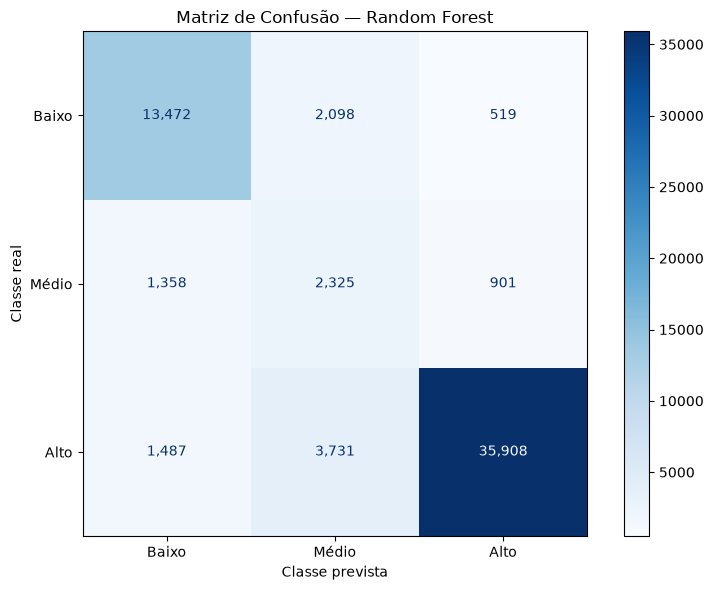

In [84]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Criar matriz de confusão do Random Forest

fig, ax = plt.subplots(figsize=(8, 6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_random_forest,
    labels=["Baixo", "Médio", "Alto"],
    cmap="Blues",
    values_format=",d",
    ax=ax
)

plt.title("Matriz de Confusão — Random Forest")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

### Análise da matriz de confusão

A matriz de confusão permite observar com mais detalhes onde o Random Forest apresentou acertos e erros.

A classe **Baixo** foi corretamente identificada em 13.472 de 16.089 observações, enquanto a classe **Alto** apresentou 35.908 classificações corretas entre 41.126 casos.

A maior dificuldade continua concentrada na classe **Médio**. Das 4.584 observações reais dessa classe, 2.325 foram classificadas corretamente, correspondendo a um recall de aproximadamente 50,7%. Entre os erros, 1.358 casos foram classificados como Baixo e 901 como Alto.

Também é possível observar que o modelo classificou como Médio algumas observações pertencentes às outras classes, principalmente 3.731 casos de Alto e 2.098 casos de Baixo. Esse comportamento ajuda a explicar a precisão relativamente baixa da classe Médio.

Mesmo com essa dificuldade, a matriz mostra que o modelo consegue distinguir de forma consistente os extremos Baixo e Alto e apresenta capacidade de identificar parte relevante dos casos intermediários.

In [85]:
# Random Forest ajustado

modelo_random_forest_ajustado = Pipeline(
    steps=[
        ("preprocessador", preprocessador),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

print("Treinamento concluído.")

Treinando Random Forest ajustado...
Treinamento concluído.


In [86]:
# Previsões do Random Forest ajustado

y_pred_rf_ajustado = modelo_random_forest_ajustado.predict(
    X_test
)


# Métricas do modelo ajustado

accuracy_rf_ajustado = accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

balanced_accuracy_rf_ajustado = balanced_accuracy_score(
    y_test,
    y_pred_rf_ajustado
)

f1_macro_rf_ajustado = f1_score(
    y_test,
    y_pred_rf_ajustado,
    average="macro"
)


print("RANDOM FOREST AJUSTADO")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_rf_ajustado:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_accuracy_rf_ajustado:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_macro_rf_ajustado:.4f}"
)

print("\nRELATÓRIO DE CLASSIFICAÇÃO")
print("=" * 65)

print(
    classification_report(
        y_test,
        y_pred_rf_ajustado,
        digits=4,
        zero_division=0
    )
)


# Comparação direta

comparacao_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

print("\nCOMPARAÇÃO")
print("=" * 65)

display(
    comparacao_rf.round(4)
)

RANDOM FOREST AJUSTADO
Accuracy:          0.8431
Balanced Accuracy: 0.7336
F1 Macro:          0.7050

RELATÓRIO DE CLASSIFICAÇÃO
              precision    recall  f1-score   support

        Alto     0.9600    0.8826    0.9197     41126
       Baixo     0.8195    0.8487    0.8338     16089
       Médio     0.2937    0.4695    0.3614      4584

    accuracy                         0.8431     61799
   macro avg     0.6911    0.7336    0.7050     61799
weighted avg     0.8740    0.8431    0.8559     61799


COMPARAÇÃO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8367,0.7392,0.704
1,Random Forest Ajustado,0.8431,0.7336,0.705


### Ajuste do Random Forest

Após o bom desempenho do Random Forest inicial, foi realizado um experimento adicional de ajuste de hiperparâmetros. O número de árvores foi aumentado de 200 para 300, a profundidade máxima passou de 20 para 30 e foram realizados ajustes nos parâmetros de regularização das folhas.

O modelo ajustado apresentou:

- **Accuracy:** 0,8431
- **Balanced Accuracy:** 0,7336
- **F1 Macro:** 0,7050

Em comparação, o Random Forest original havia apresentado:

- **Accuracy:** 0,8367
- **Balanced Accuracy:** 0,7392
- **F1 Macro:** 0,7040

O ajuste aumentou a acurácia e produziu apenas uma pequena melhoria no F1 Macro. Entretanto, a Balanced Accuracy diminuiu e o recall da classe Médio caiu de 0,5072 para 0,4695.

Isso mostra que o aumento da complexidade do modelo não produziu uma melhoria consistente em todas as métricas. Como a classe Médio é minoritária e representa uma das principais dificuldades do problema, a comparação entre os modelos deve considerar não apenas a acurácia geral, mas também o equilíbrio de desempenho entre as três classes.

Por isso, os dois modelos serão mantidos na comparação final, considerando o compromisso entre desempenho global e capacidade de reconhecer as classes minoritárias.

In [87]:
# Comparação dos modelos treinados até o momento

comparacao_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_baseline,
        accuracy_logistico,
        accuracy_random_forest,
        accuracy_rf_ajustado
    ],
    "Balanced Accuracy": [
        balanced_accuracy_baseline,
        balanced_accuracy_logistico,
        balanced_accuracy_random_forest,
        balanced_accuracy_rf_ajustado
    ],
    "F1 Macro": [
        f1_macro_baseline,
        f1_macro_logistico,
        f1_macro_random_forest,
        f1_macro_rf_ajustado
    ]
})

comparacao_modelos = (
    comparacao_modelos
    .sort_values(
        "F1 Macro",
        ascending=False
    )
    .reset_index(drop=True)
)

print("COMPARAÇÃO DOS MODELOS")
print("=" * 65)

display(
    comparacao_modelos.round(4)
)

COMPARAÇÃO DOS MODELOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest Ajustado,0.8431,0.7336,0.7050
1,Random Forest,0.8367,0.7392,0.7040
2,Regressão Logística,0.6800,0.5903,0.5538
3,Dummy Classifier,0.6655,0.3333,0.2664


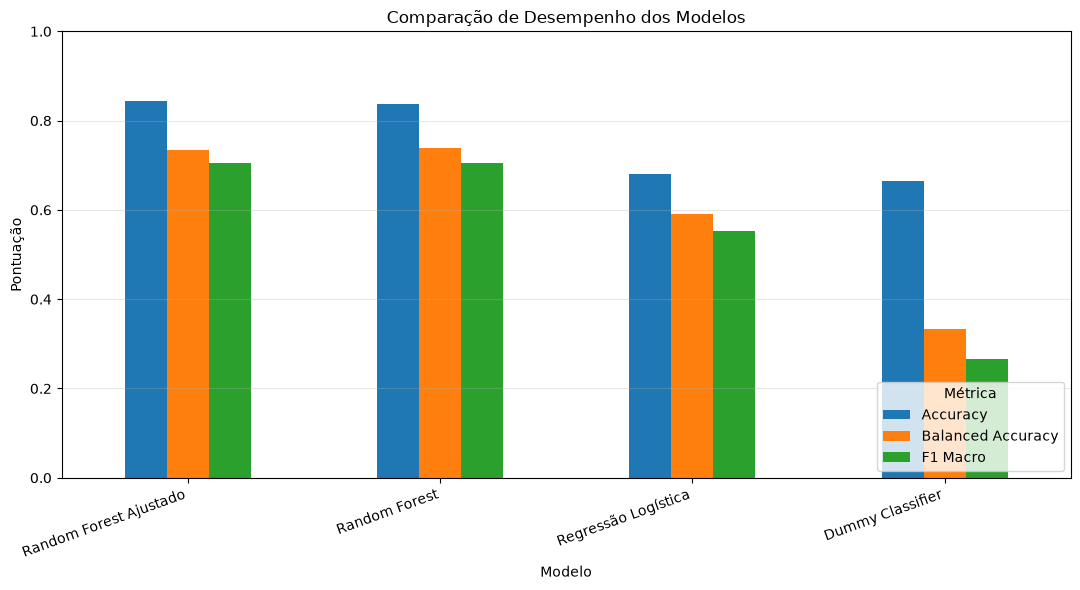

In [88]:
import matplotlib.pyplot as plt

# Preparar dados para o gráfico

comparacao_plot = (
    comparacao_modelos
    .set_index("Modelo")[
        ["Accuracy", "Balanced Accuracy", "F1 Macro"]
    ]
)

# Criar gráfico

ax = comparacao_plot.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Comparação de Desempenho dos Modelos")
plt.xlabel("Modelo")
plt.ylabel("Pontuação")
plt.ylim(0, 1)

plt.xticks(
    rotation=20,
    ha="right"
)

plt.legend(
    title="Métrica",
    loc="lower right"
)

plt.grid(
    axis="y",
    alpha=0.3
)

plt.tight_layout()
plt.show()

### Comparação dos modelos

A comparação dos modelos mostra uma evolução clara de desempenho ao longo da etapa de modelagem.

O `DummyClassifier`, utilizado como baseline, apresentou acurácia de 0,6655, mas Balanced Accuracy de apenas 0,3333 e F1 Macro de 0,2664. Isso ocorre porque o modelo simplesmente favorece a classe majoritária e não consegue distinguir adequadamente os diferentes níveis de risco.

A Regressão Logística apresentou uma melhoria importante, principalmente no equilíbrio entre as classes, alcançando F1 Macro de 0,5538 e Balanced Accuracy de 0,5903.

Os melhores resultados foram obtidos pelos modelos Random Forest. O modelo original alcançou **F1 Macro de 0,7040 e Balanced Accuracy de 0,7392**, enquanto a versão ajustada apresentou **F1 Macro de 0,7050 e acurácia de 0,8431**.

Apesar de o Random Forest ajustado apresentar a maior acurácia e um F1 Macro ligeiramente superior, a diferença de F1 Macro entre as duas versões foi de apenas 0,001. Além disso, o Random Forest original apresentou maior Balanced Accuracy e melhor recall para a classe Médio.

Dessa forma, o experimento mostra que o aumento da complexidade do Random Forest não gerou uma melhoria uniforme. Os dois modelos apresentam desempenho muito semelhante, mas com diferentes compromissos entre desempenho global e capacidade de identificar a classe minoritária.

## Correção da agregação de precipitação

Durante a revisão do processamento meteorológico, foi identificado um ponto que precisava ser corrigido na agregação diária da variável `precipitacao_total`.

Ao utilizar uma soma convencional, dias em que **todas as medições horárias de precipitação estavam ausentes** poderiam ser representados incorretamente como precipitação igual a zero. Isso confundiria duas situações diferentes:

- ausência real de precipitação;
- ausência de informação meteorológica.

Para preservar essa distinção, a agregação será refeita utilizando `sum(min_count=1)`. Dessa forma, quando todas as observações de precipitação de uma estação em determinado dia estiverem ausentes, o resultado permanecerá como `NaN`.

Após essa correção, as bases meteorológicas serão reprocessadas e reintegradas. A base de modelagem e os modelos também serão reconstruídos a partir dos dados corrigidos, garantindo que os resultados finais apresentados no restante do notebook utilizem essa versão.

In [89]:
def processar_estacao_inmet(caminho):
    df = pd.read_csv(
        caminho,
        sep=";",
        skiprows=8,
        encoding="latin-1",
        decimal=","
    )

    # Remover coluna extra criada pelo separador final dos arquivos
    colunas_extras = [
        coluna for coluna in df.columns
        if str(coluna).startswith("Unnamed:")
    ]

    df = df.drop(columns=colunas_extras)

    if df.shape[1] != 19:
        raise ValueError(
            f"Esperadas 19 colunas meteorológicas, "
            f"mas foram encontradas {df.shape[1]}"
        )

    df.columns = nomes_padronizados

    # Recuperar código da estação a partir do nome do arquivo
    codigo_estacao = caminho.name.split("_")[3]

    df["id_estacao"] = codigo_estacao

    # Converter data
    df["data"] = pd.to_datetime(
        df["data"],
        format="%Y/%m/%d",
        errors="coerce"
    )

    # Agregação diária
    diario = (
        df.groupby(
            ["id_estacao", "data"],
            as_index=False
        )
        .agg(
            # min_count=1 mantém NaN quando TODAS
            # as observações de precipitação do dia são ausentes
            precipitacao_total=(
                "precipitacao_total",
                lambda x: x.sum(min_count=1)
            ),

            pressao_atm_media=(
                "pressao_atm_hora",
                "mean"
            ),

            radiacao_global_media=(
                "radiacao_global",
                "mean"
            ),

            temperatura_media=(
                "temperatura_bulbo_hora",
                "mean"
            ),

            temperatura_max=(
                "temperatura_max",
                "max"
            ),

            temperatura_min=(
                "temperatura_min",
                "min"
            ),

            umidade_rel_media=(
                "umidade_rel_hora",
                "mean"
            ),

            umidade_rel_max=(
                "umidade_rel_max",
                "max"
            ),

            umidade_rel_min=(
                "umidade_rel_min",
                "min"
            ),

            vento_rajada_max=(
                "vento_rajada_max",
                "max"
            ),

            vento_velocidade_media=(
                "vento_velocidade",
                "mean"
            )
        )
    )

    return diario


print("Função corrigida com sucesso.")

Função corrigida com sucesso.


In [90]:
# Reprocessar todos os arquivos meteorológicos de 2024
# utilizando a função corrigida

pasta_inmet_2024 = DATA_RAW / "BDMEP_2024"

arquivos_2024 = sorted(
    pasta_inmet_2024.glob("*.CSV")
)

dados_2024_corrigidos = []
erros_2024 = []

print("REPROCESSAMENTO INMET 2024")
print("=" * 65)

print(
    f"Arquivos encontrados: "
    f"{len(arquivos_2024)}"
)

for arquivo in arquivos_2024:
    try:
        diario = processar_estacao_inmet(arquivo)
        dados_2024_corrigidos.append(diario)

    except Exception as erro:
        erros_2024.append(
            {
                "arquivo": arquivo.name,
                "erro": str(erro)
            }
        )


meteorologia_2024_diaria_corrigida = pd.concat(
    dados_2024_corrigidos,
    ignore_index=True
)


print("\nRESULTADO")
print("=" * 65)

print(
    f"Arquivos processados com sucesso: "
    f"{len(dados_2024_corrigidos)}"
)

print(
    f"Arquivos com erro: "
    f"{len(erros_2024)}"
)

print(
    f"Dimensão: "
    f"{meteorologia_2024_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2024_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2024_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2024_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2024_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)

REPROCESSAMENTO INMET 2024
Arquivos encontrados: 565

RESULTADO
Arquivos processados com sucesso: 565
Arquivos com erro: 0
Dimensão: (206790, 13)
Estações: 565
Período: 2024-01-01 00:00:00 até 2024-12-31 00:00:00
Precipitação ausente: 48,024


In [91]:
# Recriar agregação diária de 2025
# preservando NaN quando todas as medições
# de precipitação do dia estiverem ausentes

meteorologia_2025_diaria_corrigida = (
    meteorologia_2025_periodo
    .groupby(
        ["id_estacao", "data"],
        as_index=False
    )
    .agg(
        precipitacao_total=(
            "precipitacao_total",
            lambda x: x.sum(min_count=1)
        ),

        pressao_atm_media=(
            "pressao_atm_hora",
            "mean"
        ),

        radiacao_global_media=(
            "radiacao_global",
            "mean"
        ),

        temperatura_media=(
            "temperatura_bulbo_hora",
            "mean"
        ),

        temperatura_max=(
            "temperatura_max",
            "max"
        ),

        temperatura_min=(
            "temperatura_min",
            "min"
        ),

        umidade_rel_media=(
            "umidade_rel_hora",
            "mean"
        ),

        umidade_rel_max=(
            "umidade_rel_max",
            "max"
        ),

        umidade_rel_min=(
            "umidade_rel_min",
            "min"
        ),

        vento_rajada_max=(
            "vento_rajada_max",
            "max"
        ),

        vento_velocidade_media=(
            "vento_velocidade",
            "mean"
        )
    )
)


print("METEOROLOGIA 2025 CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_2025_diaria_corrigida.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_2025_diaria_corrigida['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_2025_diaria_corrigida['data'].min()} "
    f"até "
    f"{meteorologia_2025_diaria_corrigida['data'].max()}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_2025_diaria_corrigida['precipitacao_total'].isna().sum():,}"
)


METEOROLOGIA 2025 CORRIGIDA
Dimensão: (24166, 13)
Estações: 562
Período: 2025-01-01 00:00:00 até 2025-02-12 00:00:00
Precipitação ausente: 7,630


In [92]:
# Substituir as versões anteriores pelas agregações corrigidas

meteorologia_2024_diaria = (
    meteorologia_2024_diaria_corrigida.copy()
)

meteorologia_2025_diaria = (
    meteorologia_2025_diaria_corrigida.copy()
)


# Combinar 2024 e 2025

meteorologia_diaria = pd.concat(
    [
        meteorologia_2024_diaria,
        meteorologia_2025_diaria
    ],
    ignore_index=True
)

meteorologia_diaria = (
    meteorologia_diaria
    .sort_values(
        ["id_estacao", "data"]
    )
    .reset_index(drop=True)
)


# Validações

print("METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025")
print("=" * 65)

print(
    f"Dimensão: "
    f"{meteorologia_diaria.shape}"
)

print(
    f"Estações: "
    f"{meteorologia_diaria['id_estacao'].nunique()}"
)

print(
    f"Período: "
    f"{meteorologia_diaria['data'].min()} "
    f"até "
    f"{meteorologia_diaria['data'].max()}"
)

duplicados = meteorologia_diaria.duplicated(
    subset=["id_estacao", "data"]
).sum()

print(
    f"Duplicados estação/data: "
    f"{duplicados:,}"
)

print(
    f"Precipitação ausente: "
    f"{meteorologia_diaria['precipitacao_total'].isna().sum():,}"
)

print("\nRegistros por ano:")

display(
    meteorologia_diaria[
        "data"
    ]
    .dt.year
    .value_counts()
    .sort_index()
    .to_frame("quantidade")
)

METEOROLOGIA DIÁRIA CORRIGIDA — 2024 + 2025
Dimensão: (230956, 13)
Estações: 565
Período: 2024-01-01 00:00:00 até 2025-02-12 00:00:00
Duplicados estação/data: 0
Precipitação ausente: 55,654

Registros por ano:


,quantidade
data,
2024,206790
2025,24166


In [93]:
# Selecionar variáveis meteorológicas corrigidas

colunas_meteorologicas = [
    "id_estacao",
    "data",
    "precipitacao_total",
    "pressao_atm_media",
    "radiacao_global_media",
    "temperatura_media",
    "temperatura_max",
    "temperatura_min",
    "umidade_rel_media",
    "umidade_rel_max",
    "umidade_rel_min",
    "vento_rajada_max",
    "vento_velocidade_media"
]

meteorologia_para_merge = (
    meteorologia_diaria[
        colunas_meteorologicas
    ]
    .copy()
)


# Recriar integração queimadas + meteorologia

base_integrada_corrigida = (
    queimadas_com_estacao
    .merge(
        meteorologia_para_merge,
        left_on=[
            "id_estacao_proxima",
            "data"
        ],
        right_on=[
            "id_estacao",
            "data"
        ],
        how="left",
        validate="many_to_one"
    )
)


print("INTEGRAÇÃO METEOROLÓGICA CORRIGIDA")
print("=" * 65)

print(
    f"Observações antes: "
    f"{len(queimadas_com_estacao):,}"
)

print(
    f"Observações depois: "
    f"{len(base_integrada_corrigida):,}"
)

print(
    f"Duplicados município/data: "
    f"{base_integrada_corrigida.duplicated(['id_municipio', 'data']).sum():,}"
)

print(
    f"Precipitação ausente após integração: "
    f"{base_integrada_corrigida['precipitacao_total'].isna().sum():,}"
)


INTEGRAÇÃO METEOROLÓGICA CORRIGIDA
Observações antes: 324,219
Observações depois: 324,219
Duplicados município/data: 0
Precipitação ausente após integração: 90,670


In [94]:
# Reintegrar os dados do MapBiomas
# à base meteorológica corrigida

base_final_corrigida = (
    base_integrada_corrigida
    .merge(
        mapbiomas_pivot,
        on="id_municipio",
        how="left",
        validate="many_to_one"
    )
)


# Substituir a versão anterior da base final
base_final = base_final_corrigida.copy()


print("BASE FINAL CORRIGIDA")
print("=" * 65)

print(
    f"Dimensão: "
    f"{base_final.shape}"
)

print(
    f"Duplicados município/data: "
    f"{base_final.duplicated(['id_municipio', 'data']).sum():,}"
)


# Verificar cobertura MapBiomas

colunas_mapbiomas = [
    coluna for coluna in base_final.columns
    if coluna.startswith("mapbiomas_classe_")
]

com_mapbiomas = (
    base_final[colunas_mapbiomas]
    .notna()
    .any(axis=1)
    .sum()
)

sem_mapbiomas = (
    len(base_final) - com_mapbiomas
)

print(
    f"Com MapBiomas: "
    f"{com_mapbiomas:,}"
)

print(
    f"Sem MapBiomas: "
    f"{sem_mapbiomas:,}"
)

print(
    f"Cobertura MapBiomas: "
    f"{com_mapbiomas / len(base_final) * 100:.2f}%"
)

print(
    f"Precipitação ausente: "
    f"{base_final['precipitacao_total'].isna().sum():,}"
)

BASE FINAL CORRIGIDA
Dimensão: (324219, 60)
Duplicados município/data: 0
Com MapBiomas: 324,027
Sem MapBiomas: 192
Cobertura MapBiomas: 99.94%
Precipitação ausente: 90,670


In [96]:
# Recriar a variável alvo após reconstrução da base final

base_final["classe_risco"] = pd.cut(
    base_final["risco_fogo_max"],
    bins=[0, 0.40, 0.70, 1.00],
    labels=["Baixo", "Médio", "Alto"],
    include_lowest=True
)

print("VARIÁVEL ALVO — BASE CORRIGIDA")
print("=" * 65)

print(
    f"Total de observações: "
    f"{len(base_final):,}"
)

print(
    f"Com classe de risco: "
    f"{base_final['classe_risco'].notna().sum():,}"
)

print(
    f"Sem classe de risco: "
    f"{base_final['classe_risco'].isna().sum():,}"
)

# Distribuição absoluta
distribuicao = (
    base_final["classe_risco"]
    .value_counts()
    .reindex(["Baixo", "Médio", "Alto"])
)

# Distribuição percentual
percentual = (
    base_final["classe_risco"]
    .value_counts(normalize=True)
    .reindex(["Baixo", "Médio", "Alto"])
    * 100
)

resultado_target = pd.DataFrame({
    "quantidade": distribuicao,
    "percentual": percentual
})

print("\nDistribuição da variável alvo:")

display(
    resultado_target.round(2)
)

VARIÁVEL ALVO — BASE CORRIGIDA
Total de observações: 324,219
Com classe de risco: 308,991
Sem classe de risco: 15,228

Distribuição da variável alvo:


,quantidade,percentual
classe_risco,,
Baixo,80447,26.04
Médio,22918,7.42
Alto,205626,66.55


In [97]:
# Criar base de modelagem corrigida

dados_modelo = (
    base_final[
        base_final["classe_risco"].notna()
    ]
    .copy()
    .reset_index(drop=True)
)

colunas_excluir = [
    "classe_risco",
    "risco_fogo_medio",
    "risco_fogo_max",
    "numero_focos",
    "potencia_radiativa_media",
    "potencia_radiativa_max",
    "dias_sem_chuva",
    "precipitacao_queimadas",
    "id_municipio",
    "id_municipio_nome",
    "sigla_uf_nome",
    "id_estacao_proxima",
    "nome_estacao_proxima",
    "id_estacao"
]

X = dados_modelo.drop(
    columns=colunas_excluir,
    errors="ignore"
)

y = dados_modelo["classe_risco"].copy()

# Criar variável temporal
X["dia_do_ano"] = X["data"].dt.dayofyear

# Remover data original das features
X = X.drop(columns=["data"])

print("BASE DE MODELAGEM CORRIGIDA")
print("=" * 60)
print("dados_modelo:", dados_modelo.shape)
print("X:", X.shape)
print("y:", y.shape)

print(
    "\nPrecipitação ausente:",
    f"{X['precipitacao_total'].isna().sum():,}"
)

print(
    "Percentual:",
    f"{X['precipitacao_total'].isna().mean() * 100:.2f}%"
)

BASE DE MODELAGEM CORRIGIDA
dados_modelo: (308991, 61)
X: (308991, 47)
y: (308991,)

Precipitação ausente: 87,056
Percentual: 28.17%


In [98]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

# ============================================================
# 1. Divisão treino/teste
# ============================================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=12345,
    stratify=y
)

# ============================================================
# 2. Identificar tipos de variáveis
# ============================================================

colunas_numericas = (
    X_train
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas = (
    X_train
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

# ============================================================
# 3. Pré-processamento
# ============================================================

pipeline_numerico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

pipeline_categorico = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico,
            colunas_numericas
        ),
        (
            "categorico",
            pipeline_categorico,
            colunas_categoricas
        )
    ]
)

# ============================================================
# 4. Random Forest original
# ============================================================

modelo_random_forest = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest original...")

modelo_random_forest.fit(
    X_train,
    y_train
)

pred_rf = modelo_random_forest.predict(
    X_test
)

# ============================================================
# 5. Random Forest ajustado
# ============================================================

modelo_random_forest_ajustado = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=300,
                max_depth=30,
                min_samples_leaf=3,
                class_weight="balanced",
                max_features="sqrt",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("Treinando Random Forest ajustado...")

modelo_random_forest_ajustado.fit(
    X_train,
    y_train
)

pred_rf_ajustado = (
    modelo_random_forest_ajustado.predict(
        X_test
    )
)

# ============================================================
# 6. Comparação
# ============================================================

resultados_corrigidos = pd.DataFrame({
    "Modelo": [
        "Random Forest",
        "Random Forest Ajustado"
    ],
    "Accuracy": [
        accuracy_score(y_test, pred_rf),
        accuracy_score(y_test, pred_rf_ajustado)
    ],
    "Balanced Accuracy": [
        balanced_accuracy_score(
            y_test,
            pred_rf
        ),
        balanced_accuracy_score(
            y_test,
            pred_rf_ajustado
        )
    ],
    "F1 Macro": [
        f1_score(
            y_test,
            pred_rf,
            average="macro"
        ),
        f1_score(
            y_test,
            pred_rf_ajustado,
            average="macro"
        )
    ]
})

print("\nRESULTADOS APÓS CORREÇÃO DA PRECIPITAÇÃO")
print("=" * 65)

display(
    resultados_corrigidos.round(4)
)

Treinando Random Forest original...
Treinando Random Forest ajustado...

RESULTADOS APÓS CORREÇÃO DA PRECIPITAÇÃO


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Random Forest,0.8367,0.7392,0.704
1,Random Forest Ajustado,0.8431,0.7336,0.705


### Resultado após a correção

Após corrigir a agregação da precipitação, toda a base de modelagem foi reconstruída e os modelos Random Forest foram treinados novamente.

A correção aumentou a quantidade de valores ausentes de precipitação representados corretamente como `NaN`, mas os resultados dos modelos permaneceram praticamente inalterados. Isso indica que, neste experimento, a correção melhorou a consistência do tratamento dos dados sem alterar de forma relevante as conclusões obtidas na comparação dos modelos.

A partir deste ponto, as análises seguintes utilizam a **base corrigida**.

In [99]:
# Verificar distribuição temporal dos dados disponíveis

distribuicao_temporal = (
    dados_modelo
    .groupby(
        dados_modelo["data"].dt.to_period("M")
    )
    .size()
    .to_frame("observacoes")
)

print("DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM")
print("=" * 60)

display(distribuicao_temporal)

DISTRIBUIÇÃO TEMPORAL DA BASE DE MODELAGEM


,observacoes
data,
2024-01,18904
2024-02,10755
2024-03,11414
2024-04,8564
2024-05,15835
2024-06,21152
2024-07,25324
2024-08,40043
2024-09,44519


In [100]:
# ============================================================
# VALIDAÇÃO TEMPORAL
# Treino: até 30/11/2024
# Teste: 01/12/2024 a 12/02/2025
# ============================================================

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Recuperar as datas da base de modelagem
datas_modelo = dados_modelo["data"].copy()

# Definir corte temporal
data_corte = pd.Timestamp("2024-12-01")

mascara_treino = datas_modelo < data_corte
mascara_teste = datas_modelo >= data_corte

# Criar conjuntos temporais
X_train_temporal = X.loc[mascara_treino].copy()
X_test_temporal = X.loc[mascara_teste].copy()

y_train_temporal = y.loc[mascara_treino].copy()
y_test_temporal = y.loc[mascara_teste].copy()

print("DIVISÃO TEMPORAL")
print("=" * 65)

print(
    f"Treino: {len(X_train_temporal):,} observações"
)

print(
    f"Teste: {len(X_test_temporal):,} observações"
)

print(
    f"\nPeríodo de treino: "
    f"{datas_modelo[mascara_treino].min().date()} "
    f"até "
    f"{datas_modelo[mascara_treino].max().date()}"
)

print(
    f"Período de teste: "
    f"{datas_modelo[mascara_teste].min().date()} "
    f"até "
    f"{datas_modelo[mascara_teste].max().date()}"
)


# ============================================================
# Recriar pré-processador usando somente o treino temporal
# ============================================================

colunas_numericas_temporal = (
    X_train_temporal
    .select_dtypes(include=["number"])
    .columns
    .tolist()
)

colunas_categoricas_temporal = (
    X_train_temporal
    .select_dtypes(
        include=["object", "string", "category"]
    )
    .columns
    .tolist()
)

pipeline_numerico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

pipeline_categorico_temporal = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessador_temporal = ColumnTransformer(
    transformers=[
        (
            "numerico",
            pipeline_numerico_temporal,
            colunas_numericas_temporal
        ),
        (
            "categorico",
            pipeline_categorico_temporal,
            colunas_categoricas_temporal
        )
    ]
)


# ============================================================
# Random Forest para validação temporal
# ============================================================

modelo_rf_temporal = Pipeline(
    steps=[
        (
            "preprocessador",
            preprocessador_temporal
        ),
        (
            "modelo",
            RandomForestClassifier(
                n_estimators=200,
                max_depth=20,
                min_samples_leaf=2,
                class_weight="balanced",
                random_state=12345,
                n_jobs=-1
            )
        )
    ]
)

print("\nTreinando modelo temporal...")

modelo_rf_temporal.fit(
    X_train_temporal,
    y_train_temporal
)

pred_temporal = modelo_rf_temporal.predict(
    X_test_temporal
)


# ============================================================
# Avaliação
# ============================================================

accuracy_temporal = accuracy_score(
    y_test_temporal,
    pred_temporal
)

balanced_temporal = balanced_accuracy_score(
    y_test_temporal,
    pred_temporal
)

f1_temporal = f1_score(
    y_test_temporal,
    pred_temporal,
    average="macro"
)

print("\nRESULTADOS — VALIDAÇÃO TEMPORAL")
print("=" * 65)

print(
    f"Accuracy:          "
    f"{accuracy_temporal:.4f}"
)

print(
    f"Balanced Accuracy: "
    f"{balanced_temporal:.4f}"
)

print(
    f"F1 Macro:          "
    f"{f1_temporal:.4f}"
)

print("\nRELATÓRIO POR CLASSE")
print("=" * 65)

print(
    classification_report(
        y_test_temporal,
        pred_temporal,
        digits=4,
        zero_division=0
    )
)

DIVISÃO TEMPORAL
Treino: 263,665 observações
Teste: 45,326 observações

Período de treino: 2024-01-01 até 2024-11-29
Período de teste: 2024-12-01 até 2025-02-12

Treinando modelo temporal...

RESULTADOS — VALIDAÇÃO TEMPORAL
Accuracy:          0.6999
Balanced Accuracy: 0.5540
F1 Macro:          0.5516

RELATÓRIO POR CLASSE
              precision    recall  f1-score   support

        Alto     0.8080    0.7305    0.7673     22519
       Baixo     0.7078    0.7934    0.7481     18502
       Médio     0.1408    0.1382    0.1395      4305

    accuracy                         0.6999     45326
   macro avg     0.5522    0.5540    0.5516     45326
weighted avg     0.7037    0.6999    0.6998     45326



### Validação temporal

Além da divisão aleatória estratificada, foi realizada uma validação temporal com o objetivo de avaliar a capacidade do modelo de generalizar para períodos futuros.

O modelo foi treinado com observações entre janeiro e novembro de 2024 e avaliado em dados posteriores, entre dezembro de 2024 e fevereiro de 2025. Essa abordagem representa um cenário mais próximo de uma aplicação real, na qual o modelo utiliza informações históricas para realizar previsões em períodos futuros.

Na divisão aleatória, o Random Forest apresentou F1 Macro de aproximadamente 0,7040 e Balanced Accuracy de 0,7392. Na validação temporal, esses valores diminuíram para 0,5516 e 0,5540, respectivamente.

A redução de desempenho indica que parte dos padrões identificados pelo modelo não permanece completamente estável ao longo do tempo. Mesmo assim, as classes Baixo e Alto mantiveram resultados relativamente consistentes, com F1-score de 0,7481 e 0,7673. A principal dificuldade ocorreu na classe Médio, cujo F1-score foi de 0,1395.

Esse resultado reforça a importância de considerar variações temporais na avaliação do modelo. Para uma aplicação futura, seria importante incorporar novos períodos de dados, realizar atualizações periódicas do modelo e acompanhar possíveis mudanças nos padrões meteorológicos e ambientais.

In [101]:
# ============================================================
# IMPORTÂNCIA DAS VARIÁVEIS — RANDOM FOREST
# ============================================================

# Recuperar o pré-processador e o modelo treinado
preprocessador_rf = (
    modelo_random_forest
    .named_steps["preprocessador"]
)

random_forest = (
    modelo_random_forest
    .named_steps["modelo"]
)

# Recuperar os nomes das features após o pré-processamento
nomes_features = (
    preprocessador_rf
    .get_feature_names_out()
)

# Importâncias calculadas pelo Random Forest
importancias = (
    random_forest
    .feature_importances_
)

# Criar DataFrame
importancia_features = pd.DataFrame({
    "feature": nomes_features,
    "importancia": importancias
})

# Limpar os prefixos criados pelo ColumnTransformer
importancia_features["feature"] = (
    importancia_features["feature"]
    .str.replace(
        "numerico__",
        "",
        regex=False
    )
    .str.replace(
        "categorico__",
        "",
        regex=False
    )
)

# Ordenar da mais importante para a menos importante
importancia_features = (
    importancia_features
    .sort_values(
        "importancia",
        ascending=False
    )
    .reset_index(drop=True)
)

print("TOP 20 VARIÁVEIS MAIS IMPORTANTES")
print("=" * 65)

display(
    importancia_features.head(20)
)

TOP 20 VARIÁVEIS MAIS IMPORTANTES


,feature,importancia
0,dia_do_ano,0.135097
1,mes,0.086162
2,latitude,0.060199
3,longitude,0.053165
4,umidade_rel_media,0.052177
5,umidade_rel_min,0.051554
6,temperatura_min,0.035660
7,umidade_rel_max,0.030448
8,temperatura_media,0.030106
9,temperatura_max,0.029094


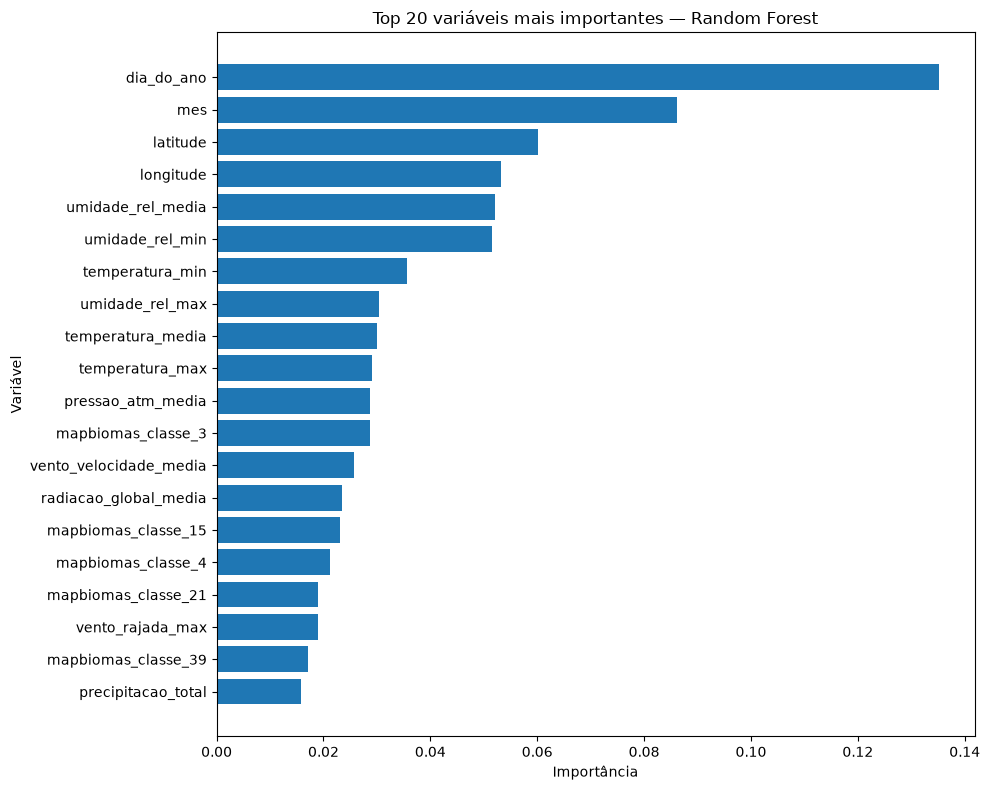

In [102]:
import matplotlib.pyplot as plt

# Selecionar as 20 variáveis mais importantes
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")

plt.title(
    "Top 20 variáveis mais importantes — Random Forest"
)

plt.tight_layout()

plt.show()

### Interpretação da importância das variáveis

A análise de importância das variáveis mostra que os componentes temporais tiveram forte participação nas previsões do Random Forest. `dia_do_ano` foi a variável individual mais importante, seguida por `mes`, indicando uma forte relação entre a sazonalidade e a classificação do risco de incêndio.

As variáveis geográficas `latitude` e `longitude` também apresentaram importância relevante, sugerindo que os padrões de risco variam espacialmente entre diferentes regiões do Brasil.

Entre as variáveis meteorológicas, destacaram-se principalmente a umidade relativa do ar e a temperatura. A umidade relativa média e mínima aparecem entre as variáveis mais importantes, acompanhadas pelas temperaturas mínima, média e máxima. Pressão atmosférica, velocidade do vento, radiação solar, rajadas de vento e precipitação também contribuíram para as previsões.

Além das condições temporais, espaciais e meteorológicas, diferentes classes de cobertura e uso da terra provenientes do MapBiomas aparecem entre as principais variáveis utilizadas pelo modelo.

Esses resultados mostram que o modelo combina informações sazonais, geográficas, meteorológicas e ambientais para realizar a classificação. Entretanto, as importâncias do Random Forest representam a contribuição das variáveis para as decisões do modelo e não devem ser interpretadas como relações causais.

In [103]:
# ============================================================
# RESUMO FINAL DOS RESULTADOS DOS MODELOS
# ============================================================

resumo_modelos = pd.DataFrame({
    "Modelo": [
        "Dummy Classifier",
        "Regressão Logística",
        "Random Forest",
        "Random Forest Ajustado",
        "Random Forest - Validação Temporal"
    ],
    
    "Accuracy": [
        0.6655,
        0.6800,
        0.8367,
        0.8431,
        0.6999
    ],
    
    "Balanced Accuracy": [
        0.3333,
        0.5903,
        0.7392,
        0.7336,
        0.5540
    ],
    
    "F1 Macro": [
        0.2664,
        0.5538,
        0.7040,
        0.7050,
        0.5516
    ]
})

print("RESUMO FINAL DOS RESULTADOS")
print("=" * 70)

display(
    resumo_modelos.round(4)
)

RESUMO FINAL DOS RESULTADOS


,Modelo,Accuracy,Balanced Accuracy,F1 Macro
0,Dummy Classifier,0.6655,0.3333,0.2664
1,Regressão Logística,0.6800,0.5903,0.5538
2,Random Forest,0.8367,0.7392,0.7040
3,Random Forest Ajustado,0.8431,0.7336,0.7050
4,Random Forest - Validação Temporal,0.6999,0.5540,0.5516


## Conclusão

Neste projeto, construí uma pipeline de Machine Learning para classificar o risco de incêndio no Brasil em três níveis: **Baixo, Médio e Alto**. Para isso, integrei informações de diferentes fontes, combinando registros de queimadas, dados meteorológicos do INMET, informações geográficas e dados de cobertura e uso da terra do MapBiomas.

Uma das partes mais desafiadoras foi a preparação dos dados. As bases apresentavam diferentes níveis de granularidade, períodos de cobertura distintos e valores ausentes. Para integrar os dados meteorológicos aos registros de queimadas, associei cada município à estação meteorológica disponível mais próxima. Essa decisão permitiu ampliar significativamente a cobertura meteorológica, embora também introduza uma limitação para municípios localizados muito longe de uma estação.

Também foi necessário tratar cuidadosamente a variável alvo. O risco diário foi construído a partir do valor máximo de `risco_fogo` observado para cada município e dia, representando uma abordagem mais conservadora, na qual prevalece o maior nível de risco registrado naquele período.

Na etapa de modelagem, utilizei um Dummy Classifier como baseline, Regressão Logística e diferentes configurações de Random Forest. Como a variável alvo apresenta forte desbalanceamento, a avaliação não foi baseada apenas em acurácia. Foram consideradas principalmente as métricas **Balanced Accuracy** e **F1 Macro**, além dos resultados individuais de cada classe.

Entre os modelos avaliados, as duas configurações de Random Forest apresentaram os melhores resultados nas principais métricas consideradas. Na divisão aleatória estratificada, o Random Forest original alcançou aproximadamente **83,67% de acurácia, 73,92% de Balanced Accuracy e F1 Macro de 0,7040**. A configuração ajustada alcançou acurácia ligeiramente superior, de **84,31%**, e F1 Macro de **0,7050**, mas apresentou Balanced Accuracy menor e redução no recall da classe Médio. Por esse motivo, mantive o Random Forest original como principal referência para interpretação.

A validação temporal trouxe uma perspectiva importante. Ao treinar o modelo com dados anteriores e avaliá-lo em um período futuro, a acurácia caiu para **69,99%**, a Balanced Accuracy para **55,40%** e o F1 Macro para **0,5516**. As classes Baixo e Alto continuaram apresentando desempenho razoável, enquanto a classe Médio foi significativamente mais difícil de identificar. Isso mostra que uma avaliação aleatória pode produzir uma visão mais otimista do desempenho e que os padrões associados ao risco de incêndio podem mudar ao longo do tempo.

A análise de importância das variáveis mostrou forte participação de fatores temporais, principalmente `dia_do_ano` e `mes`, seguidos por localização geográfica, umidade, temperatura e diferentes classes de cobertura do solo. Esses resultados indicam que o modelo utiliza uma combinação de sazonalidade, localização, condições meteorológicas e características ambientais para realizar suas classificações.

### Limitações

É importante destacar que a base de queimadas utilizada contém registros de eventos detectados. Portanto, o modelo desenvolvido neste projeto **não estima diretamente a probabilidade de ocorrer ou não um novo incêndio em qualquer município brasileiro**. A tarefa realizada consiste em prever a **categoria de risco de fogo derivada do indicador `risco_fogo` do INPE para observações município-dia presentes na base de queimadas**.

Essa distinção é importante porque um modelo de previsão da ocorrência de novos incêndios exigiria também exemplos de municípios e dias sem registros de focos, permitindo construir explicitamente uma classe de não ocorrência.

Outra limitação é que os dados do MapBiomas utilizados correspondem ao ano de 2021 e foram tratados como características ambientais estáticas para o período de 2024–2025. Além disso, a associação meteorológica utiliza a estação disponível mais próxima e, em algumas regiões com baixa densidade de estações, essa distância pode ser elevada.

Os valores meteorológicos ausentes foram tratados dentro da pipeline de Machine Learning utilizando a mediana calculada somente sobre os dados de treinamento, reduzindo o risco de vazamento de informações entre treino e teste.

Finalmente, as importâncias produzidas pelo Random Forest indicam quais variáveis foram mais utilizadas pelo modelo para realizar suas decisões, mas **não representam relações causais**.

### Próximos passos

Como evolução deste trabalho, seria interessante construir uma base completa de municípios e dias, incluindo períodos sem focos de incêndio, permitindo transformar o problema em uma previsão direta da ocorrência de queimadas. Também seria possível incorporar dados mais recentes de cobertura do solo, testar estratégias específicas para melhorar a identificação da classe Médio e utilizar validação temporal contínua para acompanhar mudanças nos padrões ambientais.

Para uma aplicação operacional, o modelo também deveria ser atualizado periodicamente com novos dados meteorológicos e ambientais, além de ter seu desempenho monitorado ao longo do tempo.

In [104]:
# ============================================================
# SALVAR RESULTADOS FINAIS DOS MODELOS
# ============================================================

caminho_resultados = (
    DATA_PROCESSED / "resultados_modelos.csv"
)

resumo_modelos.to_csv(
    caminho_resultados,
    index=False,
    encoding="utf-8-sig"
)

print(
    "Arquivo salvo com sucesso em:"
)

print(caminho_resultados)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\resultados_modelos.csv


In [105]:
# ============================================================
# SALVAR IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

caminho_importancias = (
    DATA_PROCESSED / "importancia_features.csv"
)

importancia_features.to_csv(
    caminho_importancias,
    index=False,
    encoding="utf-8-sig"
)

print("Arquivo salvo com sucesso em:")
print(caminho_importancias)

Arquivo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\data\processed\importancia_features.csv


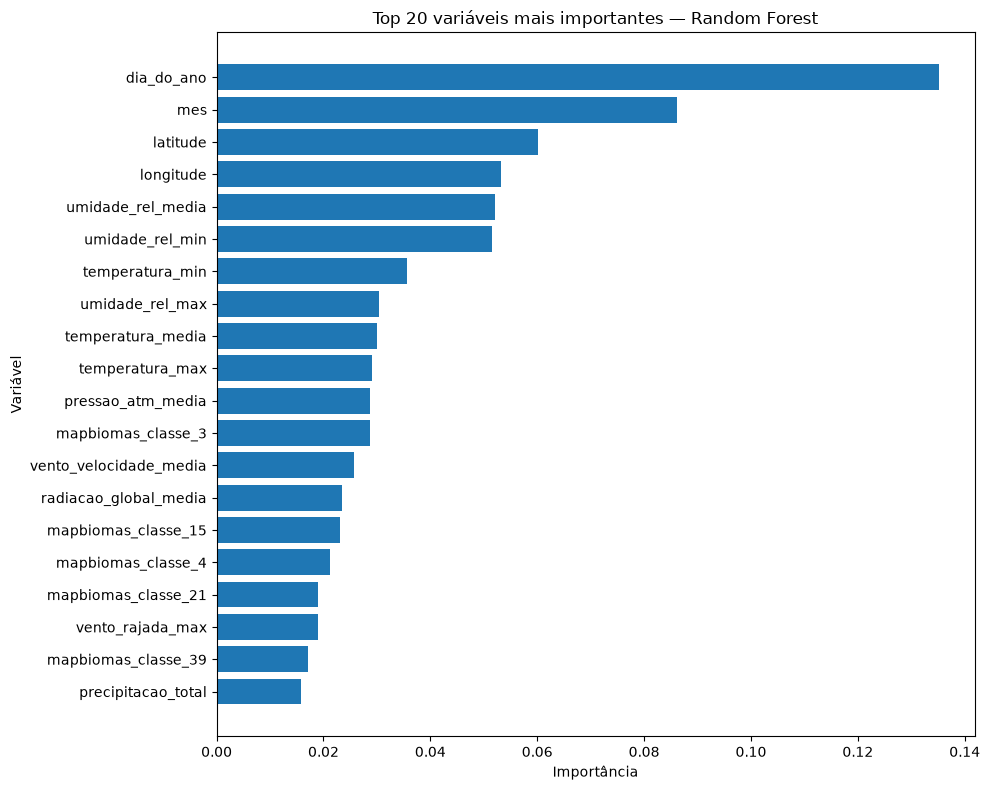

Gráfico salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\figures\feature_importance_random_forest.png


In [106]:
# ============================================================
# SALVAR GRÁFICO DE IMPORTÂNCIA DAS VARIÁVEIS
# ============================================================

FIGURES_DIR = PROJECT_ROOT / "figures"

# Garantir que a pasta existe
FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Selecionar Top 20
top20 = (
    importancia_features
    .head(20)
    .sort_values("importancia", ascending=True)
)

plt.figure(figsize=(10, 8))

plt.barh(
    top20["feature"],
    top20["importancia"]
)

plt.xlabel("Importância")
plt.ylabel("Variável")
plt.title(
    "Top 20 variáveis mais importantes — Random Forest"
)

plt.tight_layout()

# Caminho da imagem
caminho_figura = (
    FIGURES_DIR / "feature_importance_random_forest.png"
)

# Salvar em boa resolução
plt.savefig(
    caminho_figura,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gráfico salvo com sucesso em:")
print(caminho_figura)

In [107]:
# ============================================================
# SALVAR MODELO RANDOM FOREST TREINADO
# ============================================================

import joblib

MODELS_DIR = PROJECT_ROOT / "models"

MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

caminho_modelo = (
    MODELS_DIR / "random_forest_risco_incendio.joblib"
)

joblib.dump(
    modelo_random_forest,
    caminho_modelo
)

print("Modelo salvo com sucesso em:")
print(caminho_modelo)

print(
    "\nTamanho do arquivo:",
    f"{caminho_modelo.stat().st_size / (1024**2):.2f} MB"
)

Modelo salvo com sucesso em:
c:\Users\Jroy\Documents\ProjetoFinalTripleTenBrazil\models\random_forest_risco_incendio.joblib

Tamanho do arquivo: 459.59 MB
